# Analyse métier - Étoile Satisfaction client

**Table Druid :** fact_review  
**Grain :** Une ligne par commande dans le Parquet avis préparé; les comptes de notes sont agrégés par commande

Ce notebook exécute cinquante visuels depuis la table Druid dénormalisée indiquée ci-dessus. La première cellule détecte une connexion accessible depuis le noyau Python : `http://127.0.0.1:25019/druid/v2/sql` sur l’hôte ou `http://druid-router:8888/druid/v2/sql` dans Docker. Pour imposer une URL, définir `DRUID_SQL_URL_OVERRIDE` ou la variable d’environnement `DRUID_SQL_URL`.

**Limite du modèle :** Le PDF présente l’étoile comme avis. Le code courant lit un Parquet reviews agrégé par commande; les lignes ne sont donc pas nécessairement des avis individuels. Les notes doivent être présentées avec leur distribution. La table ne contient pas catégorie/produit, et ne permet pas de calculer la couverture d’avis sans rapprochement maîtrisé avec fact_order.

**Source du modèle :** [20_build_ebrasil_warehouse.py](https://github.com/rbizoi/FormationBigDataBI/blob/master/spark/jobs/20_build_ebrasil_warehouse.py), blob GitHub `8b553b3970eb8f3f5804ac0072569cfade518c57`. Le script produit les six tables dénormalisées ; `docker/ebrasil-druid/ingest.py` les ingère sous les mêmes noms, sans rollup. Au démarrage, le notebook contrôle les six tables et les colonnes utilisées par ses graphiques via `INFORMATION_SCHEMA.COLUMNS`, ainsi que la présence de lignes dans sa table. Aucune donnée de démonstration ni dimension séparée n’est utilisée. La compatibilité du schéma est contrôlée ; la provenance des lignes dépend de l’initialisation eBrasil du dépôt.


In [1]:
import os
import socket
import warnings
from pathlib import Path
from urllib.parse import urlsplit, urlunsplit
import requests
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# None : sélection automatique depuis le noyau Python, indépendamment du navigateur.
# Pour imposer une adresse, renseigner ceci ou la variable d'environnement DRUID_SQL_URL.
DRUID_SQL_URL_OVERRIDE = None
HOST_SQL_URL = "http://127.0.0.1:25019/druid/v2/sql"
DOCKER_SQL_URL = "http://druid-router:8888/druid/v2/sql"
TABLE = "fact_review"
MODEL_TABLES = ["fact_logistics","fact_order","fact_order_item","fact_payment","fact_review","mart_customer_rfm"]
REQUIRED_COLUMNS = ["answer_hours_sum","customer_city","customer_state","customer_unique_id","customer_zip_code","purchase_date_calendar_date","purchase_date_iso_week","purchase_date_quarter","purchase_date_weekday","purchase_date_year","purchase_time_day_part","purchase_time_hour","review_count","score_1","score_5","score_sum","status","text_review_groups"]
MODEL_SOURCE = "https://github.com/rbizoi/FormationBigDataBI/blob/master/spark/jobs/20_build_ebrasil_warehouse.py"
MODEL_SOURCE_BLOB_SHA = "8b553b3970eb8f3f5804ac0072569cfade518c57"

def normalize_sql_url(value):
    parsed = urlsplit(value.strip())
    if parsed.scheme not in ("http", "https") or not parsed.hostname:
        raise ValueError("DRUID_SQL_URL doit être une URL HTTP complète, sans syntaxe Markdown.")
    if parsed.username or parsed.password or parsed.query or parsed.fragment:
        raise ValueError("Ne pas inclure d'identifiants, de paramètres ou de fragment dans DRUID_SQL_URL.")
    netloc = parsed.netloc
    if parsed.hostname == "druid-router" and parsed.port == 25019:
        warnings.warn("Port corrigé : druid-router utilise 8888 ; 25019 est le port de l'hôte.")
        netloc = "druid-router:8888"
    if parsed.hostname in ("localhost", "127.0.0.1") and parsed.port == 8888:
        warnings.warn("Port hôte corrigé selon le dépôt : 127.0.0.1:25019.")
        netloc = "127.0.0.1:25019"
    path = parsed.path.rstrip("/") or "/druid/v2/sql"
    if path != "/druid/v2/sql":
        raise ValueError("Le point d'accès attendu est /druid/v2/sql.")
    return urlunsplit((parsed.scheme, netloc, path, "", ""))

def select_druid_url():
    explicit = DRUID_SQL_URL_OVERRIDE or os.getenv("DRUID_SQL_URL", "").strip()
    try:
        socket.getaddrinfo("druid-router", 8888)
        docker_dns = True
    except OSError:
        docker_dns = False
    in_docker = Path("/.dockerenv").exists() or docker_dns
    candidates = [DOCKER_SQL_URL, HOST_SQL_URL] if in_docker else [HOST_SQL_URL, DOCKER_SQL_URL]
    if explicit:
        candidates = [normalize_sql_url(explicit)]
    errors = []
    for url in candidates:
        try:
            response = requests.post(url, json={"query": "SELECT 1 AS connexion_ok", "resultFormat": "object"}, timeout=(3, 8))
            response.raise_for_status()
            result = response.json()
            if not isinstance(result, list) or not result or result[0].get("connexion_ok") != 1:
                raise ValueError("Ce service ne répond pas comme Druid SQL.")
            return url
        except (requests.RequestException, ValueError) as exc:
            errors.append(f"{url} : {exc}")
    raise ConnectionError(
        "Connexion Druid impossible depuis ce noyau Python.\nWindows : " + HOST_SQL_URL +
        "\nDocker du dépôt : " + DOCKER_SQL_URL +
        "\nVérifier druid-router et le réseau Docker. Corriger ou supprimer la variable DRUID_SQL_URL si elle est définie.\n" +
        "\n".join(errors)
    )

DRUID_SQL_URL = select_druid_url()

def druid_sql(sql):
    try:
        response = requests.post(DRUID_SQL_URL,
            json={"query": sql, "resultFormat": "object",
                  "context": {"sqlTimeZone": "UTC", "useApproximateCountDistinct": False}}, timeout=(5, 120))
    except requests.RequestException as exc:
        raise ConnectionError(f"Druid inaccessible à {DRUID_SQL_URL}. Relancer la cellule de connexion.") from exc
    if not response.ok:
        raise RuntimeError(f"Druid SQL HTTP {response.status_code}\nSQL : {sql}\n{response.text[:3000]}")
    data = response.json()
    if not isinstance(data, list):
        raise ValueError("Druid doit renvoyer une liste d'objets JSON.")
    return pd.DataFrame(data)

# Toutes les données analysées proviennent des tables dénormalisées exposées par Druid.
model_names = ", ".join("'" + name + "'" for name in MODEL_TABLES)
schema = druid_sql(
    'SELECT TABLE_NAME AS "table_name", COLUMN_NAME AS "column_name", DATA_TYPE AS "data_type" '
    "FROM INFORMATION_SCHEMA.COLUMNS WHERE TABLE_SCHEMA = 'druid' AND TABLE_NAME IN (" + model_names + ")"
)
if schema.empty:
    raise RuntimeError("Aucune étoile eBrasil dans Druid : exécuter l'initialisation du dépôt.")
missing_tables = set(MODEL_TABLES) - set(schema["table_name"])
if missing_tables:
    raise RuntimeError("Tables Druid manquantes : " + ", ".join(sorted(missing_tables)))
present_columns = set(schema.loc[schema["table_name"] == TABLE, "column_name"])
missing_columns = set(REQUIRED_COLUMNS) - present_columns
if missing_columns:
    raise RuntimeError(f"Schéma incompatible pour {TABLE}. Colonnes dénormalisées manquantes : " +
        ", ".join(sorted(missing_columns)) + ". Reconstruire avec 20_build_ebrasil_warehouse.py puis réingérer dans Druid.")
row_count = int(druid_sql(f'SELECT COUNT(*) AS lignes FROM "{TABLE}"').iloc[0]["lignes"])
if row_count == 0:
    raise RuntimeError(f"La table Druid {TABLE} est vide.")
print("Druid SQL :", DRUID_SQL_URL)
print(f"Table : {TABLE} | {row_count:,} lignes | {len(REQUIRED_COLUMNS)} colonnes contrôlées")
print("Source du modèle :", MODEL_SOURCE)
display(schema.loc[schema["table_name"] == TABLE].reset_index(drop=True))


Druid SQL : http://127.0.0.1:25019/druid/v2/sql
Table : fact_review | 100,000 lignes | 18 colonnes contrôlées
Source du modèle : https://github.com/rbizoi/FormationBigDataBI/blob/master/spark/jobs/20_build_ebrasil_warehouse.py


,table_name,column_name,data_type
0,fact_review,__time,TIMESTAMP
1,fact_review,order_id,VARCHAR
2,fact_review,customer_unique_id,VARCHAR
3,fact_review,status,VARCHAR
4,fact_review,average_score,VARCHAR
5,fact_review,purchase_date_key,VARCHAR
6,fact_review,purchase_time_key,VARCHAR
7,fact_review,customer_customer_id,VARCHAR
8,fact_review,customer_zip_code,VARCHAR
9,fact_review,customer_city,VARCHAR


In [2]:
def build_chart_sql(spec):
    """Construit une requête Druid avec des alias délimités, y compris VALUE."""
    dim, metric, kind = spec["dim"], spec["metric"], spec["kind"]
    fields = [dim["sql"] + ' AS "x"']
    if dim.get("series"):
        fields.append(dim["series"] + ' AS "series"')
    fields.append(metric["sql"] + ' AS "value"')
    group_by = "1, 2" if dim.get("series") else "1"
    order_by = '"x"' if kind == "line" else '"value" DESC'
    table_name = TABLE.replace('"', '""')
    return ('SELECT ' + ', '.join(fields) + ' FROM "' + table_name +
            '" GROUP BY ' + group_by + ' ORDER BY ' + order_by + ' LIMIT 40')

def numeric_chart_values(values, title):
    """Convertit les nombres Druid et conserve les valeurs absentes comme manquantes."""
    converted = pd.to_numeric(values, errors="coerce").astype("float64")
    converted = converted.replace([float("inf"), float("-inf")], float("nan"))
    invalid = values.notna() & converted.isna()
    if invalid.any():
        print(f"{title} : {int(invalid.sum())} valeur(s) non numérique(s) ou non finie(s) écartée(s).")
    return converted

def run_chart(spec):
    dim,metric,kind=spec["dim"],spec["metric"],spec["kind"]
    if dim["type"]=="client":
        xcol=dim["sql"].replace('"',""); frame=rfm.copy(); scol=(dim.get("series") or "").replace('"',"")
        if xcol not in frame.columns: raise KeyError("Dimension RFM manquante: "+xcol)
        if metric["pandas"] != "customer_unique_id":
            metric_column = metric["pandas"]
            frame[metric_column] = numeric_chart_values(frame[metric_column], spec["title"])
            frame = frame.dropna(subset=[metric_column])
        if frame.empty:
            print("Aucune valeur numérique disponible pour", spec["title"])
            return
        by=[xcol]+([scol] if scol else [])
        if metric["pandas"]=="customer_unique_id": grouped=frame.groupby(by,dropna=False)["customer_unique_id"].nunique().reset_index(name="value")
        else:
            agg="sum" if metric["pandas"]=="monetary" else "mean"
            grouped=frame.groupby(by,dropna=False)[metric["pandas"]].agg(agg).reset_index(name="value")
        if scol: grouped=grouped.pivot(index=xcol,columns=scol,values="value").fillna(0).head(25)
        else: grouped=grouped.sort_values("value",ascending=False).head(25).set_index(xcol)["value"]
    else:
        sql = build_chart_sql(spec)
        result=druid_sql(sql)
        if result.empty: print("Aucune donnée pour",spec["title"]); return
        if "value" not in result.columns:
            raise ValueError("La réponse Druid ne contient pas la colonne attendue 'value'.")
        result["value"] = numeric_chart_values(result["value"], spec["title"])
        result = result.dropna(subset=["value"])
        if result.empty:
            print("Aucune valeur numérique disponible pour", spec["title"], "(résultat NULL ou non numérique).")
            return
        if dim.get("series"): grouped=result.pivot_table(index="x",columns="series",values="value",aggfunc="sum",fill_value=0).head(25)
        else:
            result=result.sort_values("x" if kind=="line" else "value",ascending=(kind=="line")); grouped=result.set_index("x")["value"].head(40)
    # Pandas doit recevoir un type numérique explicite, y compris pour Decimal et les chaînes JSON.
    if isinstance(grouped, pd.DataFrame):
        grouped = grouped.apply(lambda column: numeric_chart_values(column, spec["title"]))
        grouped = grouped.dropna(axis=0, how="all").dropna(axis=1, how="all")
    else:
        grouped = numeric_chart_values(grouped, spec["title"]).dropna()
    if grouped.empty:
        print("Aucune valeur numérique disponible pour", spec["title"])
        return
    if kind == "scatter" and not isinstance(grouped, pd.DataFrame):
        numeric_x = pd.to_numeric(pd.Series(grouped.index), errors="coerce").astype("float64")
        valid_x = numeric_x.notna() & ~numeric_x.isin([float("inf"), float("-inf")])
        if not valid_x.any():
            print("Aucune abscisse numérique disponible pour", spec["title"])
            return
        grouped = grouped.iloc[valid_x.to_numpy()]
        numeric_x = numeric_x.loc[valid_x]
    fig,ax=plt.subplots(figsize=(10,5))
    if isinstance(grouped,pd.DataFrame):
        if kind=="heatmap":
            img=ax.imshow(grouped.values,aspect="auto",cmap="YlGnBu")
            ax.set_yticks(range(len(grouped.index))); ax.set_yticklabels([str(v) for v in grouped.index])
            ax.set_xticks(range(len(grouped.columns))); ax.set_xticklabels([str(v) for v in grouped.columns],rotation=45,ha="right")
            fig.colorbar(img,ax=ax,label=metric["label"])
        else: grouped.plot(kind="bar",stacked=True,ax=ax,colormap="tab20"); ax.legend(title="Série",bbox_to_anchor=(1.02,1),loc="upper left")
    elif kind=="line": grouped.plot(kind="line",marker="o",ax=ax,color="#148A8A"); ax.tick_params(axis="x",rotation=45)
    elif kind=="scatter": ax.scatter(numeric_x.to_numpy(),grouped.to_numpy(dtype=float),color="#148A8A",alpha=.75)
    else: grouped.plot(kind="bar",ax=ax,color="#148A8A"); ax.tick_params(axis="x",rotation=45)
    ax.set_title(spec["title"]); ax.set_xlabel(dim["label"]); ax.set_ylabel(metric["label"])
    fig.tight_layout(); plt.show(); plt.close(fig)


## 1. Niveau et distribution des notes

Mesurer la satisfaction avec une moyenne pondérée et la distribution complète des scores, en évitant de résumer l’ordinal par une seule moyenne.

**Drill-down :** Score > date d’achat > statut > géographie client; comparaison des volumes avant toute interprétation.

Visuel 1 - Niveau et distribution des notes - Mois achat


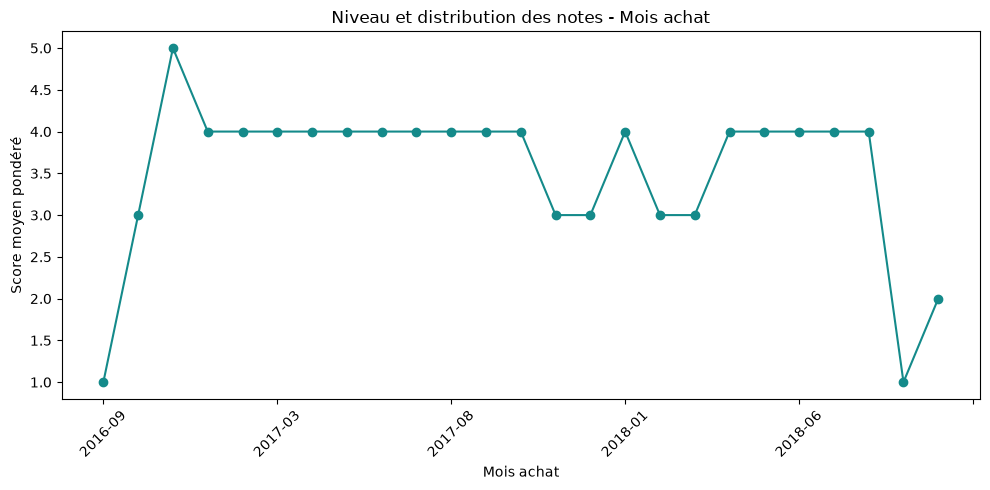

Visuel 2 - Niveau et distribution des notes - Année achat


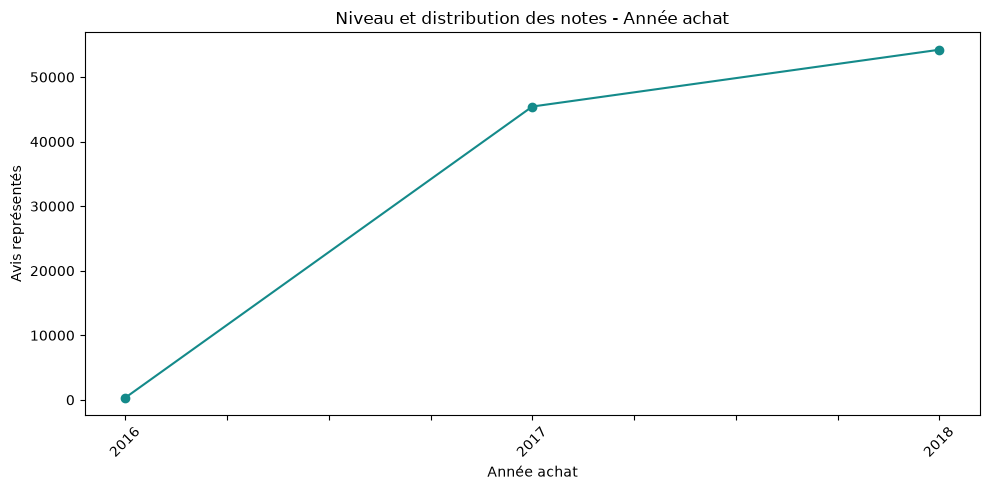

Visuel 3 - Niveau et distribution des notes - État client
Aucune valeur numérique disponible pour Niveau et distribution des notes - État client (résultat NULL ou non numérique).
Visuel 4 - Niveau et distribution des notes - Ville client
Aucune valeur numérique disponible pour Niveau et distribution des notes - Ville client (résultat NULL ou non numérique).
Visuel 5 - Niveau et distribution des notes - Statut


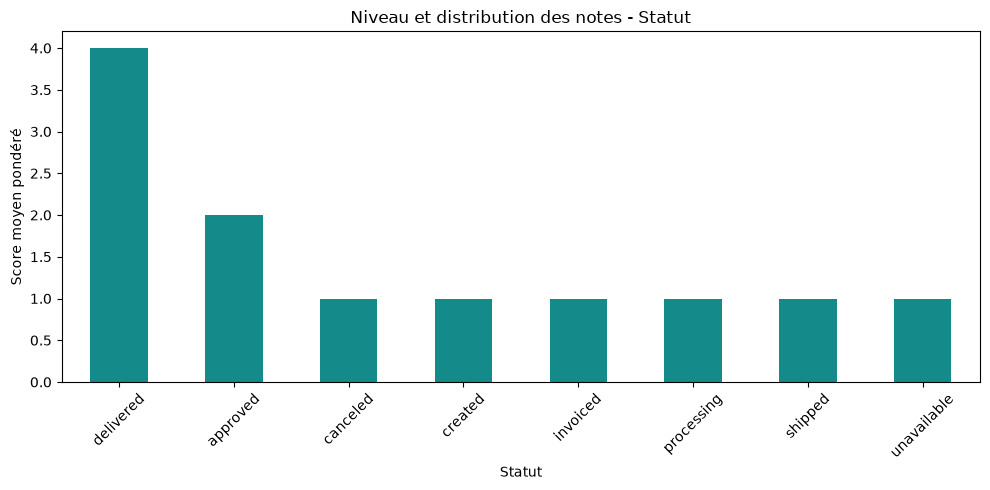

Visuel 6 - Niveau et distribution des notes - Jour semaine


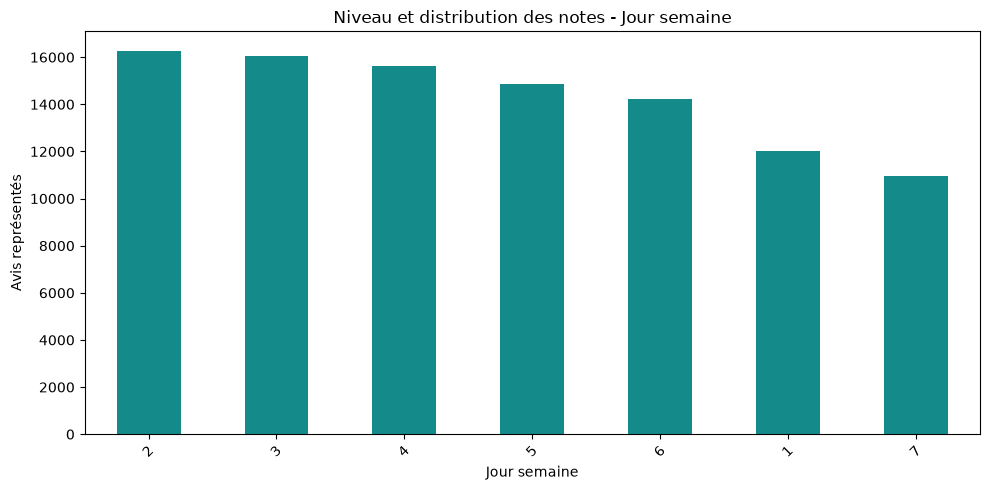

Visuel 7 - Niveau et distribution des notes - Partie du jour
Aucune valeur numérique disponible pour Niveau et distribution des notes - Partie du jour (résultat NULL ou non numérique).
Visuel 8 - Niveau et distribution des notes - État x statut
Aucune valeur numérique disponible pour Niveau et distribution des notes - État x statut (résultat NULL ou non numérique).
Visuel 9 - Niveau et distribution des notes - Mois x statut


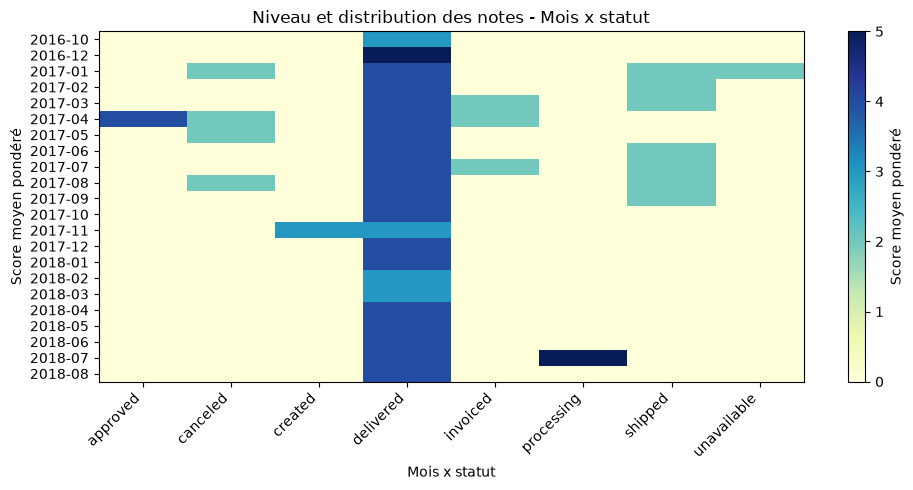

Visuel 10 - Niveau et distribution des notes - Client unique


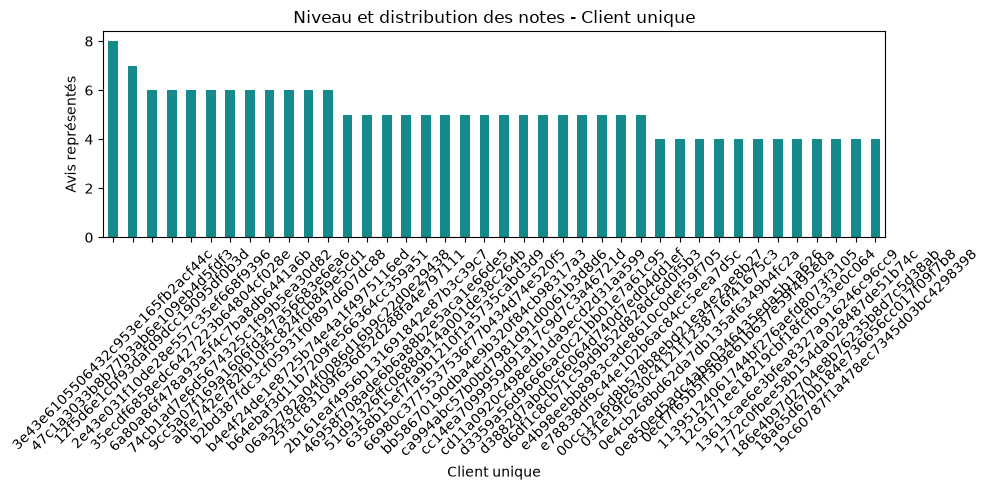

In [3]:
CHARTS=[
  {
    "n": 1,
    "title": "Niveau et distribution des notes - Mois achat",
    "dim": {
      "label": "Mois achat",
      "sql": "SUBSTRING(\"purchase_date_calendar_date\",1,7)",
      "type": "temporal",
      "series": None
    },
    "metric": {
      "label": "Score moyen pondéré",
      "sql": "SUM(\"score_sum\") / NULLIF(SUM(\"review_count\"),0)",
      "pandas": "score_sum"
    },
    "kind": "line"
  },
  {
    "n": 2,
    "title": "Niveau et distribution des notes - Année achat",
    "dim": {
      "label": "Année achat",
      "sql": "\"purchase_date_year\"",
      "type": "temporal",
      "series": None
    },
    "metric": {
      "label": "Avis représentés",
      "sql": "SUM(\"review_count\")",
      "pandas": "review_count"
    },
    "kind": "line"
  },
  {
    "n": 3,
    "title": "Niveau et distribution des notes - État client",
    "dim": {
      "label": "État client",
      "sql": "\"customer_state\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Score 1",
      "sql": "SUM(\"score_1\")",
      "pandas": "score_1"
    },
    "kind": "bar"
  },
  {
    "n": 4,
    "title": "Niveau et distribution des notes - Ville client",
    "dim": {
      "label": "Ville client",
      "sql": "\"customer_city\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Score 5",
      "sql": "SUM(\"score_5\")",
      "pandas": "score_5"
    },
    "kind": "bar"
  },
  {
    "n": 5,
    "title": "Niveau et distribution des notes - Statut",
    "dim": {
      "label": "Statut",
      "sql": "\"status\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Score moyen pondéré",
      "sql": "SUM(\"score_sum\") / NULLIF(SUM(\"review_count\"),0)",
      "pandas": "score_sum"
    },
    "kind": "bar"
  },
  {
    "n": 6,
    "title": "Niveau et distribution des notes - Jour semaine",
    "dim": {
      "label": "Jour semaine",
      "sql": "\"purchase_date_weekday\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Avis représentés",
      "sql": "SUM(\"review_count\")",
      "pandas": "review_count"
    },
    "kind": "bar"
  },
  {
    "n": 7,
    "title": "Niveau et distribution des notes - Partie du jour",
    "dim": {
      "label": "Partie du jour",
      "sql": "\"purchase_time_day_part\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Score 1",
      "sql": "SUM(\"score_1\")",
      "pandas": "score_1"
    },
    "kind": "bar"
  },
  {
    "n": 8,
    "title": "Niveau et distribution des notes - État x statut",
    "dim": {
      "label": "État x statut",
      "sql": "\"customer_state\"",
      "type": "categorical",
      "series": "\"status\""
    },
    "metric": {
      "label": "Score 5",
      "sql": "SUM(\"score_5\")",
      "pandas": "score_5"
    },
    "kind": "heatmap"
  },
  {
    "n": 9,
    "title": "Niveau et distribution des notes - Mois x statut",
    "dim": {
      "label": "Mois x statut",
      "sql": "SUBSTRING(\"purchase_date_calendar_date\",1,7)",
      "type": "temporal",
      "series": "\"status\""
    },
    "metric": {
      "label": "Score moyen pondéré",
      "sql": "SUM(\"score_sum\") / NULLIF(SUM(\"review_count\"),0)",
      "pandas": "score_sum"
    },
    "kind": "heatmap"
  },
  {
    "n": 10,
    "title": "Niveau et distribution des notes - Client unique",
    "dim": {
      "label": "Client unique",
      "sql": "\"customer_unique_id\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Avis représentés",
      "sql": "SUM(\"review_count\")",
      "pandas": "review_count"
    },
    "kind": "bar"
  }
]
for chart in CHARTS:
    print("Visuel",chart["n"],"-",chart["title"])
    run_chart(chart)


## 2. Évolution temporelle de la satisfaction

Suivre notes et volumes dans le temps pour distinguer tendance du score et variation du volume représenté.

**Drill-down :** Année > trimestre > mois > jour d’achat; partie du jour/heure; statut et état client en segmentation.

Visuel 1 - Évolution temporelle de la satisfaction - Mois achat


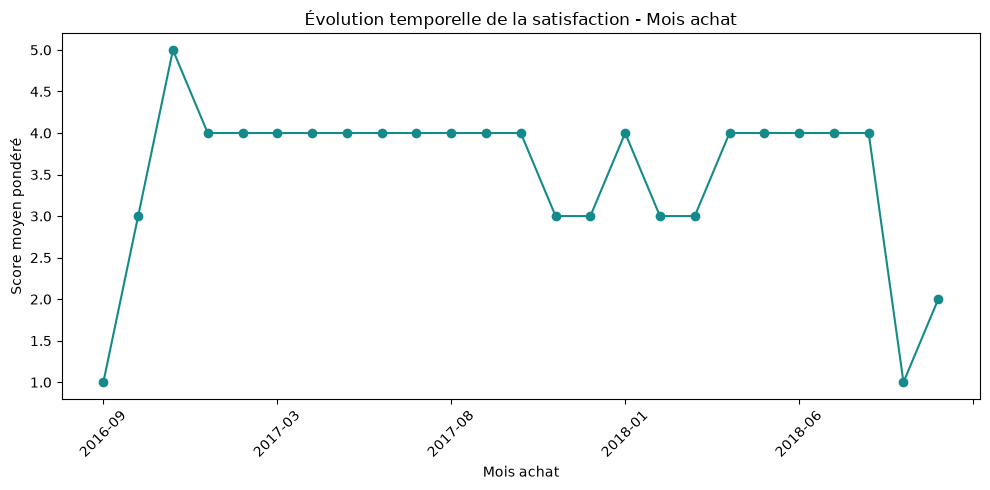

Visuel 2 - Évolution temporelle de la satisfaction - Trimestre achat


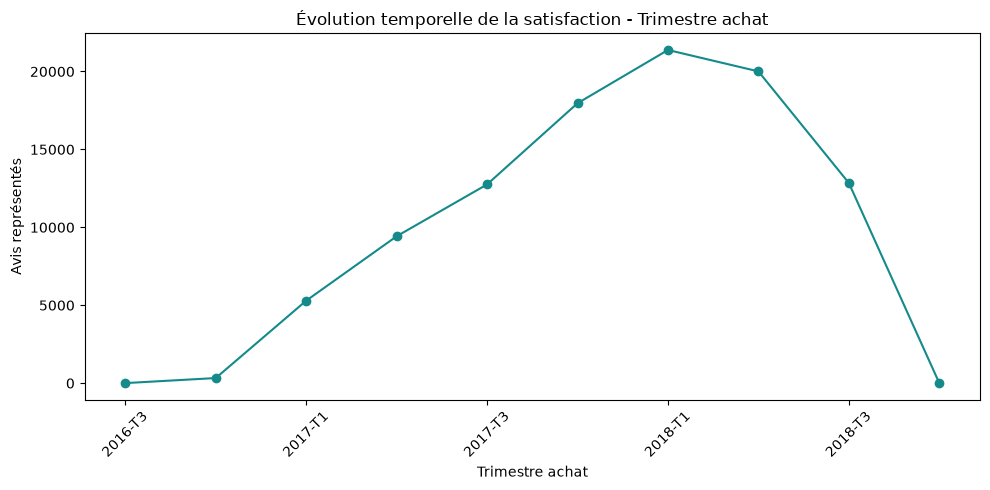

Visuel 3 - Évolution temporelle de la satisfaction - Jour achat


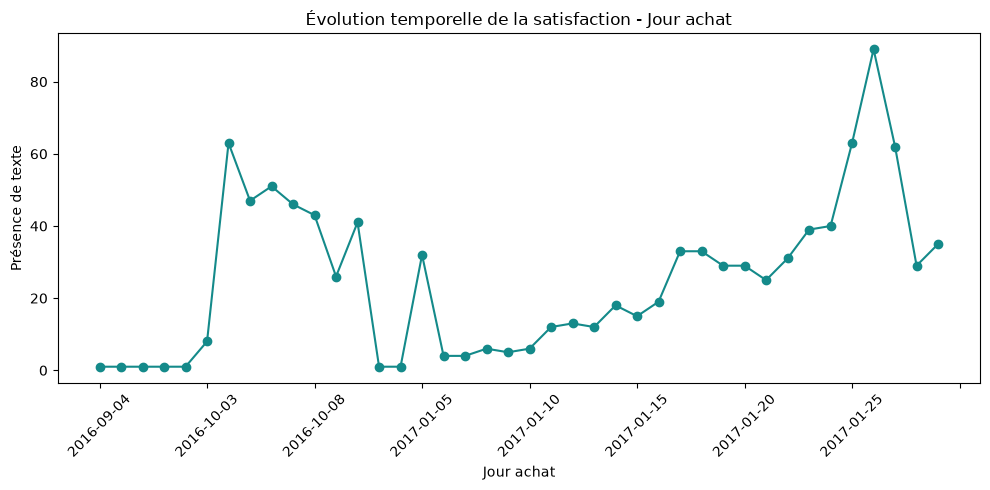

Visuel 4 - Évolution temporelle de la satisfaction - Semaine ISO


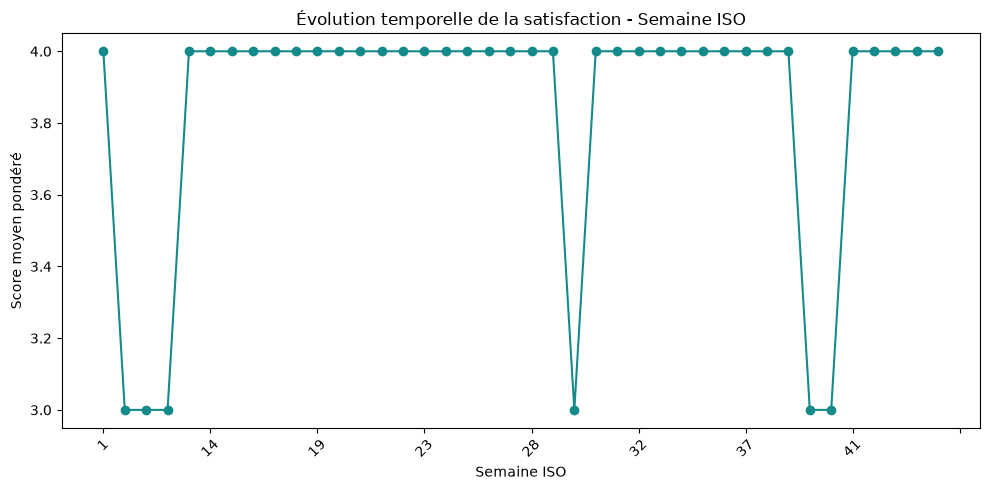

Visuel 5 - Évolution temporelle de la satisfaction - Jour semaine


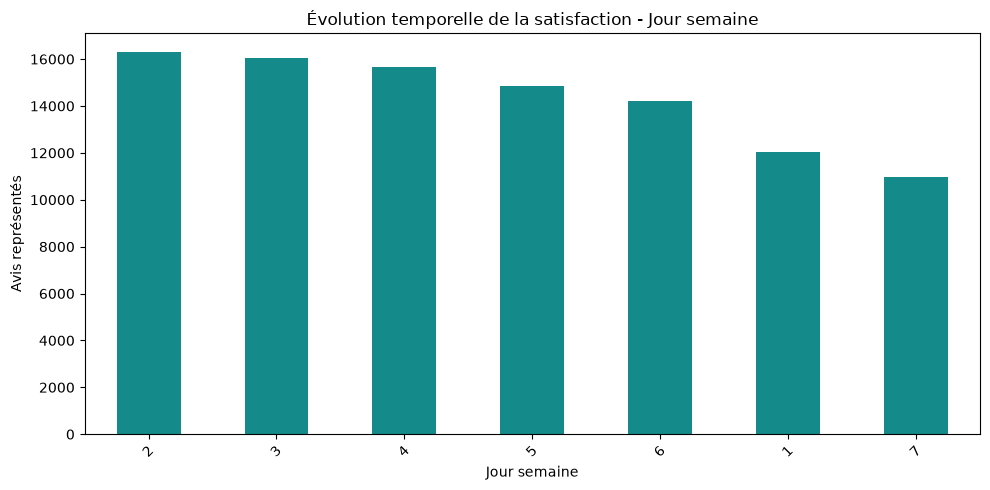

Visuel 6 - Évolution temporelle de la satisfaction - Heure achat


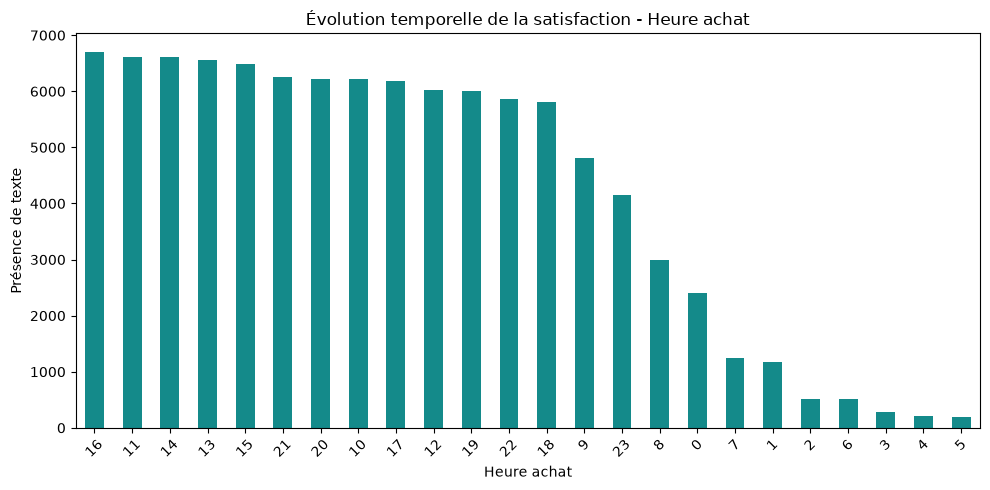

Visuel 7 - Évolution temporelle de la satisfaction - Partie du jour


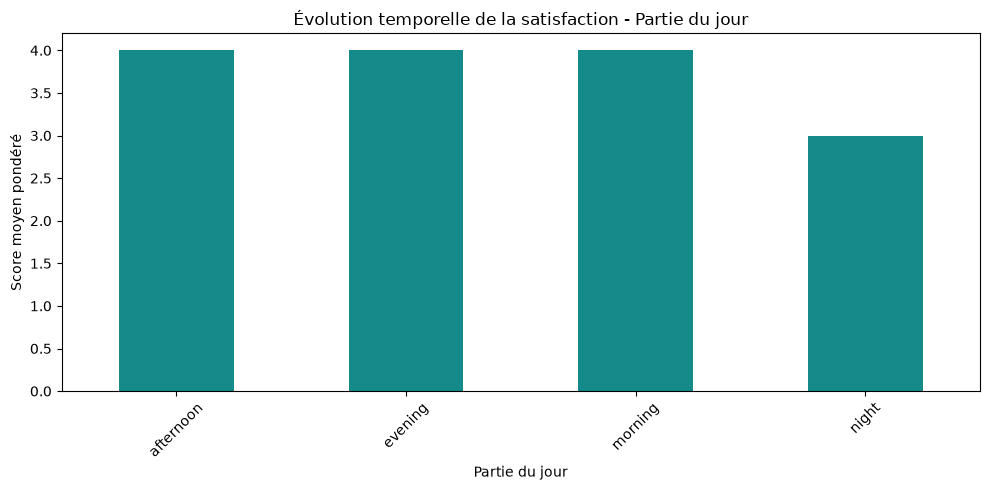

Visuel 8 - Évolution temporelle de la satisfaction - Mois x statut


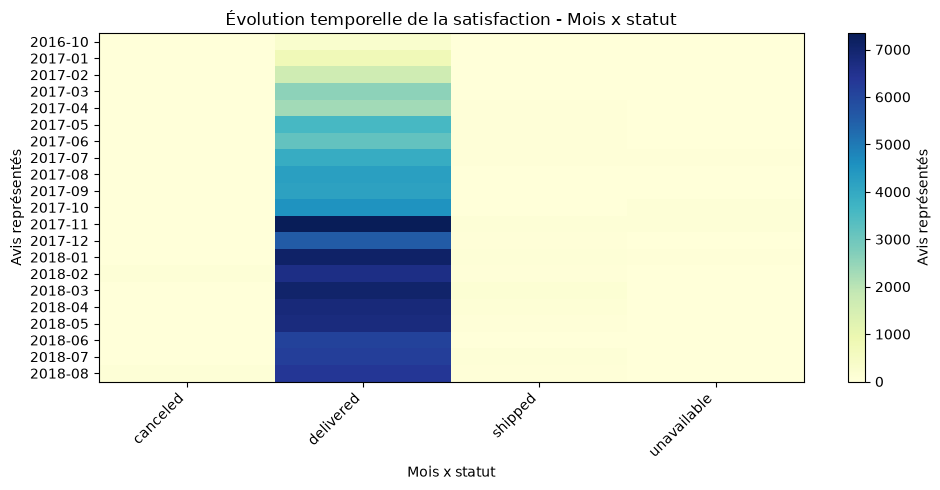

Visuel 9 - Évolution temporelle de la satisfaction - État x mois


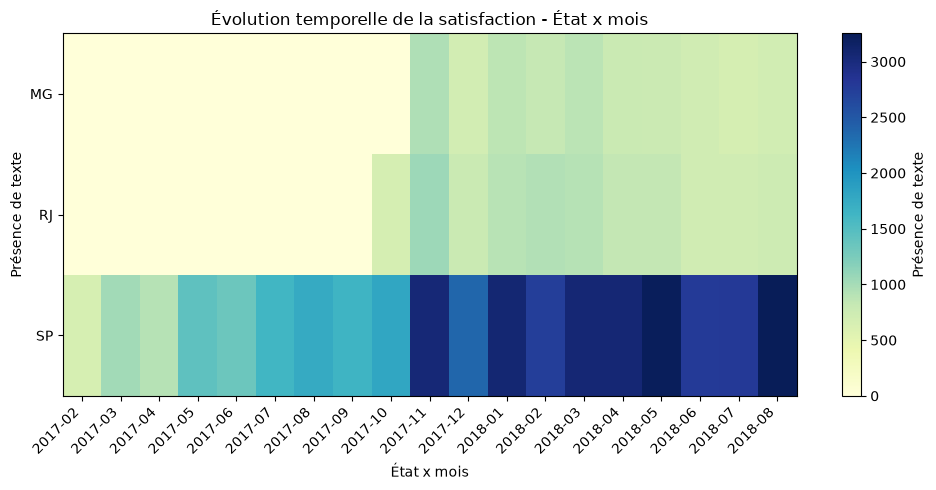

Visuel 10 - Évolution temporelle de la satisfaction - Statut


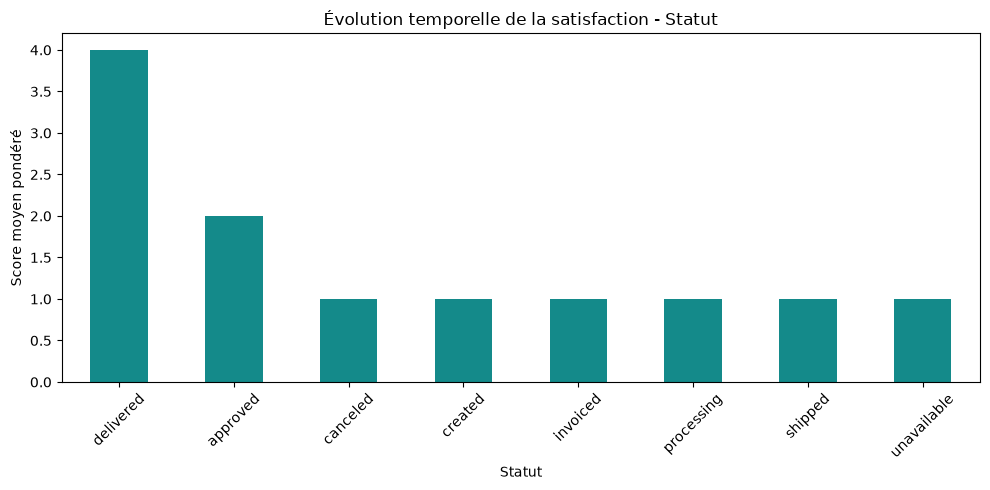

In [4]:
CHARTS=[
  {
    "n": 1,
    "title": "Évolution temporelle de la satisfaction - Mois achat",
    "dim": {
      "label": "Mois achat",
      "sql": "SUBSTRING(\"purchase_date_calendar_date\",1,7)",
      "type": "temporal",
      "series": None
    },
    "metric": {
      "label": "Score moyen pondéré",
      "sql": "SUM(\"score_sum\") / NULLIF(SUM(\"review_count\"),0)",
      "pandas": "score_sum"
    },
    "kind": "line"
  },
  {
    "n": 2,
    "title": "Évolution temporelle de la satisfaction - Trimestre achat",
    "dim": {
      "label": "Trimestre achat",
      "sql": "CONCAT(CAST(\"purchase_date_year\" AS VARCHAR), '-T', CAST(\"purchase_date_quarter\" AS VARCHAR))",
      "type": "temporal",
      "series": None
    },
    "metric": {
      "label": "Avis représentés",
      "sql": "SUM(\"review_count\")",
      "pandas": "review_count"
    },
    "kind": "line"
  },
  {
    "n": 3,
    "title": "Évolution temporelle de la satisfaction - Jour achat",
    "dim": {
      "label": "Jour achat",
      "sql": "\"purchase_date_calendar_date\"",
      "type": "temporal",
      "series": None
    },
    "metric": {
      "label": "Présence de texte",
      "sql": "SUM(\"text_review_groups\")",
      "pandas": "text_review_groups"
    },
    "kind": "line"
  },
  {
    "n": 4,
    "title": "Évolution temporelle de la satisfaction - Semaine ISO",
    "dim": {
      "label": "Semaine ISO",
      "sql": "\"purchase_date_iso_week\"",
      "type": "numeric",
      "series": None
    },
    "metric": {
      "label": "Score moyen pondéré",
      "sql": "SUM(\"score_sum\") / NULLIF(SUM(\"review_count\"),0)",
      "pandas": "score_sum"
    },
    "kind": "line"
  },
  {
    "n": 5,
    "title": "Évolution temporelle de la satisfaction - Jour semaine",
    "dim": {
      "label": "Jour semaine",
      "sql": "\"purchase_date_weekday\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Avis représentés",
      "sql": "SUM(\"review_count\")",
      "pandas": "review_count"
    },
    "kind": "bar"
  },
  {
    "n": 6,
    "title": "Évolution temporelle de la satisfaction - Heure achat",
    "dim": {
      "label": "Heure achat",
      "sql": "\"purchase_time_hour\"",
      "type": "numeric",
      "series": None
    },
    "metric": {
      "label": "Présence de texte",
      "sql": "SUM(\"text_review_groups\")",
      "pandas": "text_review_groups"
    },
    "kind": "bar"
  },
  {
    "n": 7,
    "title": "Évolution temporelle de la satisfaction - Partie du jour",
    "dim": {
      "label": "Partie du jour",
      "sql": "\"purchase_time_day_part\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Score moyen pondéré",
      "sql": "SUM(\"score_sum\") / NULLIF(SUM(\"review_count\"),0)",
      "pandas": "score_sum"
    },
    "kind": "bar"
  },
  {
    "n": 8,
    "title": "Évolution temporelle de la satisfaction - Mois x statut",
    "dim": {
      "label": "Mois x statut",
      "sql": "SUBSTRING(\"purchase_date_calendar_date\",1,7)",
      "type": "temporal",
      "series": "\"status\""
    },
    "metric": {
      "label": "Avis représentés",
      "sql": "SUM(\"review_count\")",
      "pandas": "review_count"
    },
    "kind": "heatmap"
  },
  {
    "n": 9,
    "title": "Évolution temporelle de la satisfaction - État x mois",
    "dim": {
      "label": "État x mois",
      "sql": "\"customer_state\"",
      "type": "categorical",
      "series": "SUBSTRING(\"purchase_date_calendar_date\",1,7)"
    },
    "metric": {
      "label": "Présence de texte",
      "sql": "SUM(\"text_review_groups\")",
      "pandas": "text_review_groups"
    },
    "kind": "heatmap"
  },
  {
    "n": 10,
    "title": "Évolution temporelle de la satisfaction - Statut",
    "dim": {
      "label": "Statut",
      "sql": "\"status\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Score moyen pondéré",
      "sql": "SUM(\"score_sum\") / NULLIF(SUM(\"review_count\"),0)",
      "pandas": "score_sum"
    },
    "kind": "bar"
  }
]
for chart in CHARTS:
    print("Visuel",chart["n"],"-",chart["title"])
    run_chart(chart)


## 3. Délai de réponse et présence de texte

Explorer les mesures de réponse et la présence de texte si les colonnes préparées sont bien des heures/sommes d’heures selon leur contrat source.

**Drill-down :** Période d’achat > statut > état/ville; délai réponse agrégé > commande; vérifier la définition des champs d’heures.

Visuel 1 - Délai de réponse et présence de texte - Mois achat


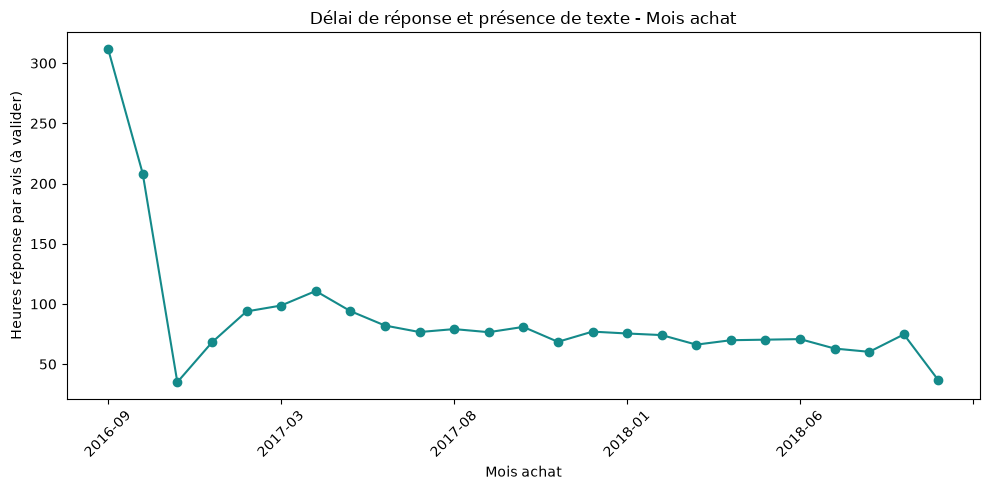

Visuel 2 - Délai de réponse et présence de texte - Statut


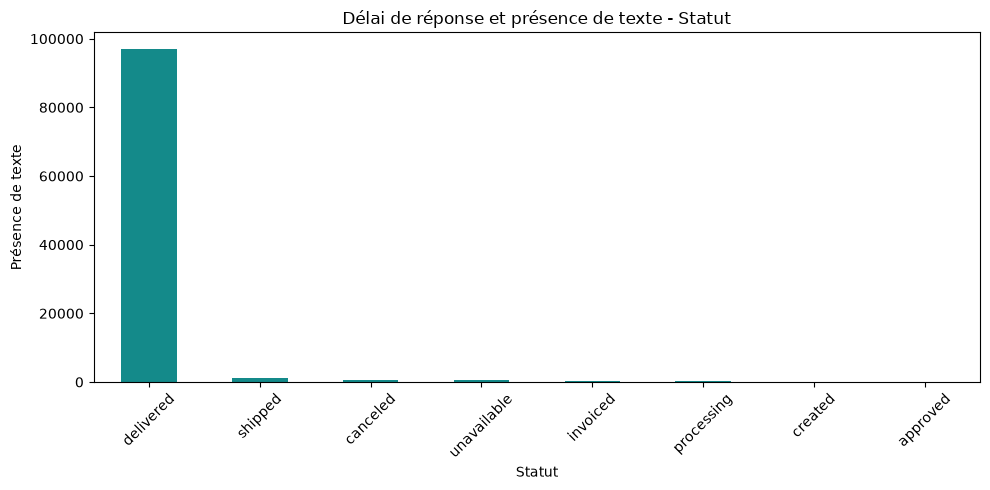

Visuel 3 - Délai de réponse et présence de texte - État client


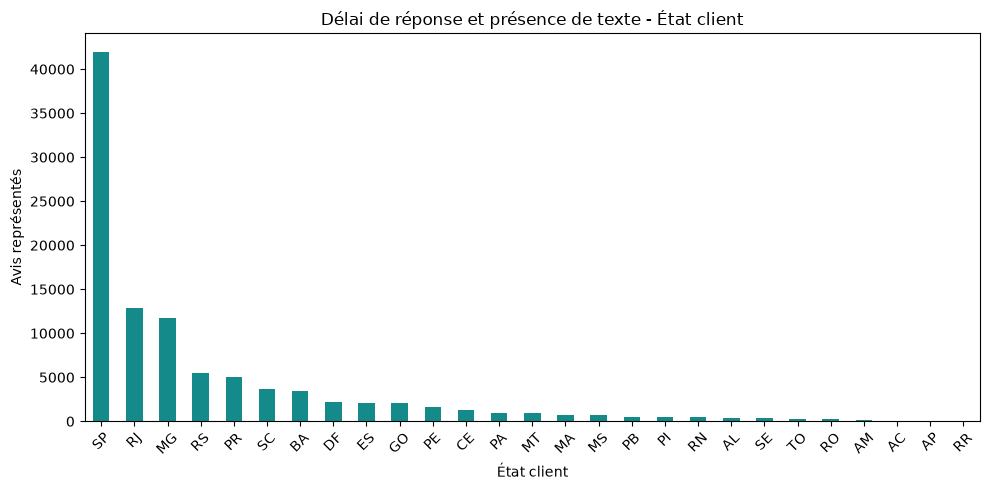

Visuel 4 - Délai de réponse et présence de texte - Ville client


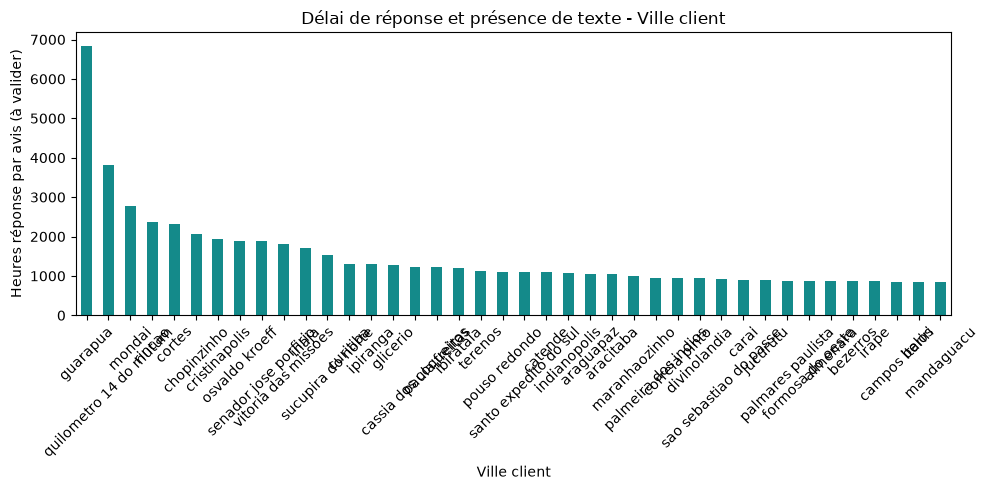

Visuel 5 - Délai de réponse et présence de texte - Jour semaine


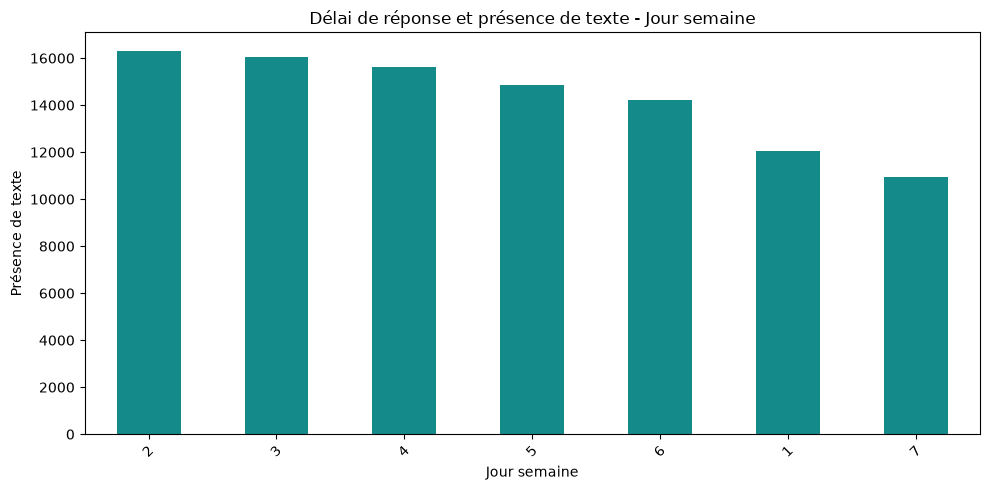

Visuel 6 - Délai de réponse et présence de texte - Partie du jour


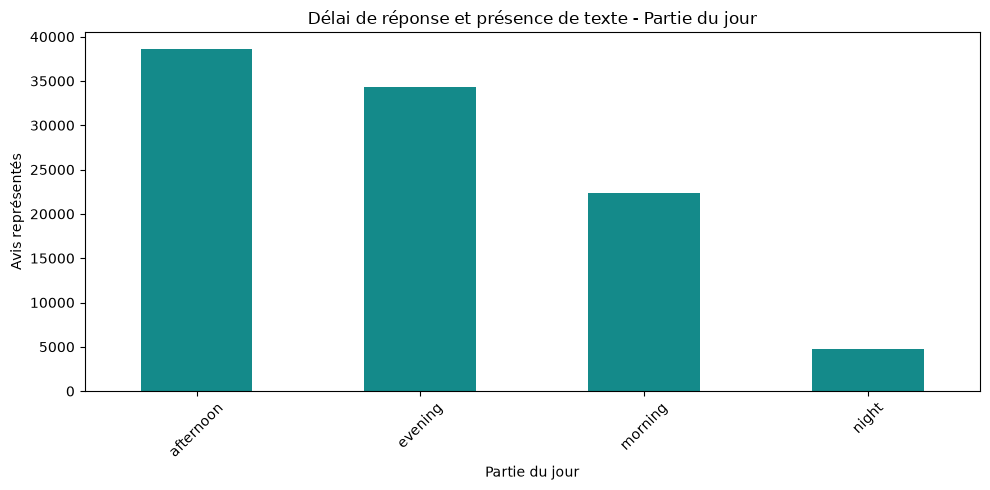

Visuel 7 - Délai de réponse et présence de texte - Présence texte par tranche


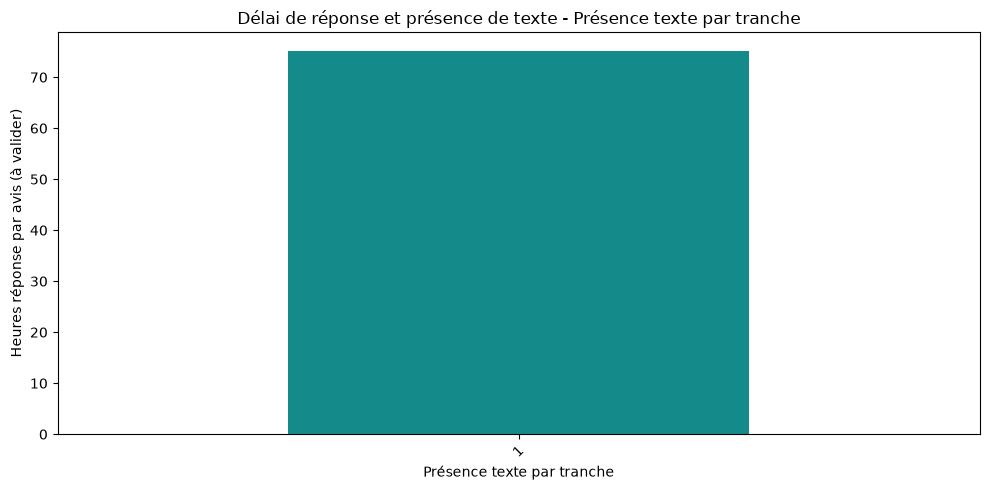

Visuel 8 - Délai de réponse et présence de texte - Mois x statut


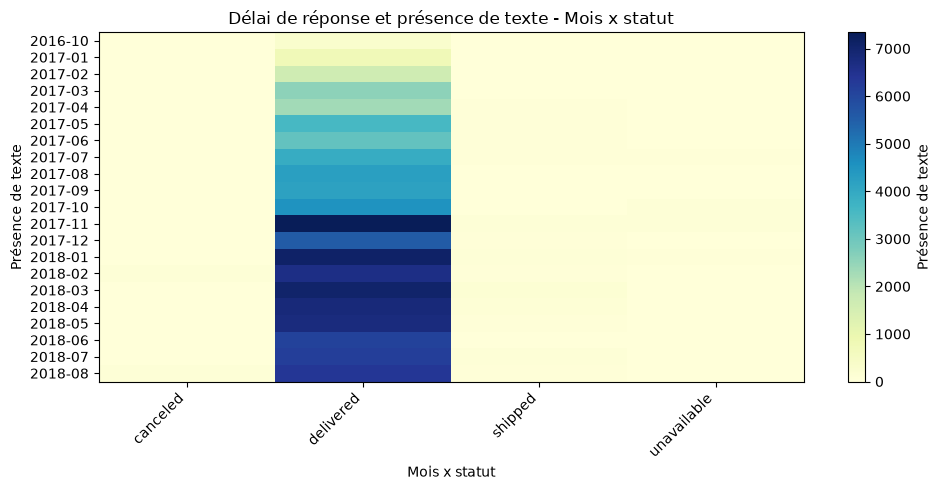

Visuel 9 - Délai de réponse et présence de texte - État x statut


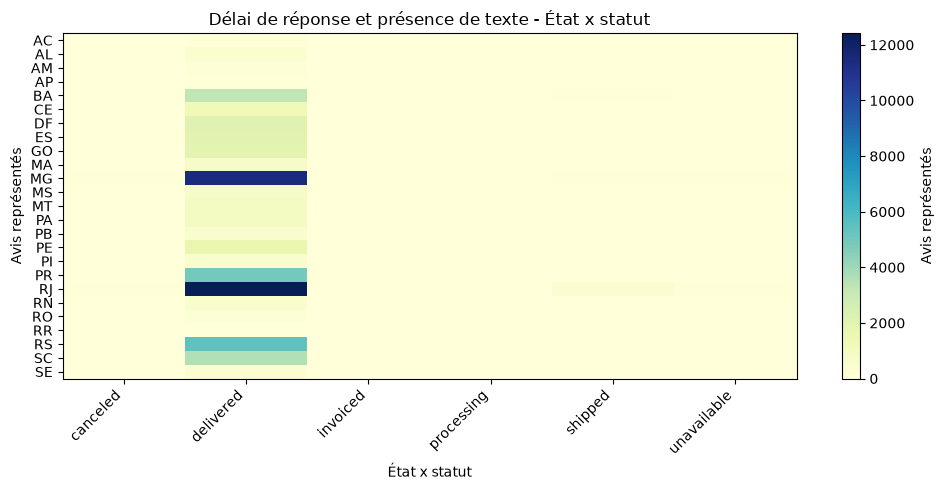

Visuel 10 - Délai de réponse et présence de texte - Client unique


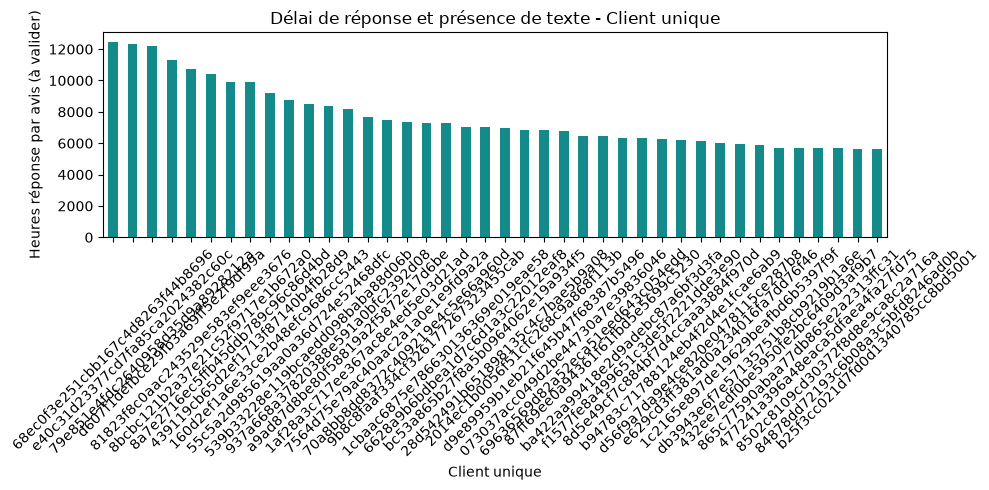

In [5]:
CHARTS=[
  {
    "n": 1,
    "title": "Délai de réponse et présence de texte - Mois achat",
    "dim": {
      "label": "Mois achat",
      "sql": "SUBSTRING(\"purchase_date_calendar_date\",1,7)",
      "type": "temporal",
      "series": None
    },
    "metric": {
      "label": "Heures réponse par avis (à valider)",
      "sql": "SUM(\"answer_hours_sum\") / NULLIF(SUM(\"review_count\"),0)",
      "pandas": "answer_hours_sum"
    },
    "kind": "line"
  },
  {
    "n": 2,
    "title": "Délai de réponse et présence de texte - Statut",
    "dim": {
      "label": "Statut",
      "sql": "\"status\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Présence de texte",
      "sql": "SUM(\"text_review_groups\")",
      "pandas": "text_review_groups"
    },
    "kind": "bar"
  },
  {
    "n": 3,
    "title": "Délai de réponse et présence de texte - État client",
    "dim": {
      "label": "État client",
      "sql": "\"customer_state\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Avis représentés",
      "sql": "SUM(\"review_count\")",
      "pandas": "review_count"
    },
    "kind": "bar"
  },
  {
    "n": 4,
    "title": "Délai de réponse et présence de texte - Ville client",
    "dim": {
      "label": "Ville client",
      "sql": "\"customer_city\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Heures réponse par avis (à valider)",
      "sql": "SUM(\"answer_hours_sum\") / NULLIF(SUM(\"review_count\"),0)",
      "pandas": "answer_hours_sum"
    },
    "kind": "bar"
  },
  {
    "n": 5,
    "title": "Délai de réponse et présence de texte - Jour semaine",
    "dim": {
      "label": "Jour semaine",
      "sql": "\"purchase_date_weekday\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Présence de texte",
      "sql": "SUM(\"text_review_groups\")",
      "pandas": "text_review_groups"
    },
    "kind": "bar"
  },
  {
    "n": 6,
    "title": "Délai de réponse et présence de texte - Partie du jour",
    "dim": {
      "label": "Partie du jour",
      "sql": "\"purchase_time_day_part\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Avis représentés",
      "sql": "SUM(\"review_count\")",
      "pandas": "review_count"
    },
    "kind": "bar"
  },
  {
    "n": 7,
    "title": "Délai de réponse et présence de texte - Présence texte par tranche",
    "dim": {
      "label": "Présence texte par tranche",
      "sql": "\"text_review_groups\"",
      "type": "numeric",
      "series": None
    },
    "metric": {
      "label": "Heures réponse par avis (à valider)",
      "sql": "SUM(\"answer_hours_sum\") / NULLIF(SUM(\"review_count\"),0)",
      "pandas": "answer_hours_sum"
    },
    "kind": "bar"
  },
  {
    "n": 8,
    "title": "Délai de réponse et présence de texte - Mois x statut",
    "dim": {
      "label": "Mois x statut",
      "sql": "SUBSTRING(\"purchase_date_calendar_date\",1,7)",
      "type": "temporal",
      "series": "\"status\""
    },
    "metric": {
      "label": "Présence de texte",
      "sql": "SUM(\"text_review_groups\")",
      "pandas": "text_review_groups"
    },
    "kind": "heatmap"
  },
  {
    "n": 9,
    "title": "Délai de réponse et présence de texte - État x statut",
    "dim": {
      "label": "État x statut",
      "sql": "\"customer_state\"",
      "type": "categorical",
      "series": "\"status\""
    },
    "metric": {
      "label": "Avis représentés",
      "sql": "SUM(\"review_count\")",
      "pandas": "review_count"
    },
    "kind": "heatmap"
  },
  {
    "n": 10,
    "title": "Délai de réponse et présence de texte - Client unique",
    "dim": {
      "label": "Client unique",
      "sql": "\"customer_unique_id\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Heures réponse par avis (à valider)",
      "sql": "SUM(\"answer_hours_sum\") / NULLIF(SUM(\"review_count\"),0)",
      "pandas": "answer_hours_sum"
    },
    "kind": "bar"
  }
]
for chart in CHARTS:
    print("Visuel",chart["n"],"-",chart["title"])
    run_chart(chart)


## 4. Écarts de satisfaction selon les segments observables

Comparer score moyen pondéré et distribution entre statuts et géographies client, avec les volumes pour repérer la fragilité des petits groupes.

**Drill-down :** État > ville > code postal; statut; période d’achat; compléter l’explication avec les analyses logistiques séparées.

Visuel 1 - Écarts de satisfaction selon les segments observables - État client


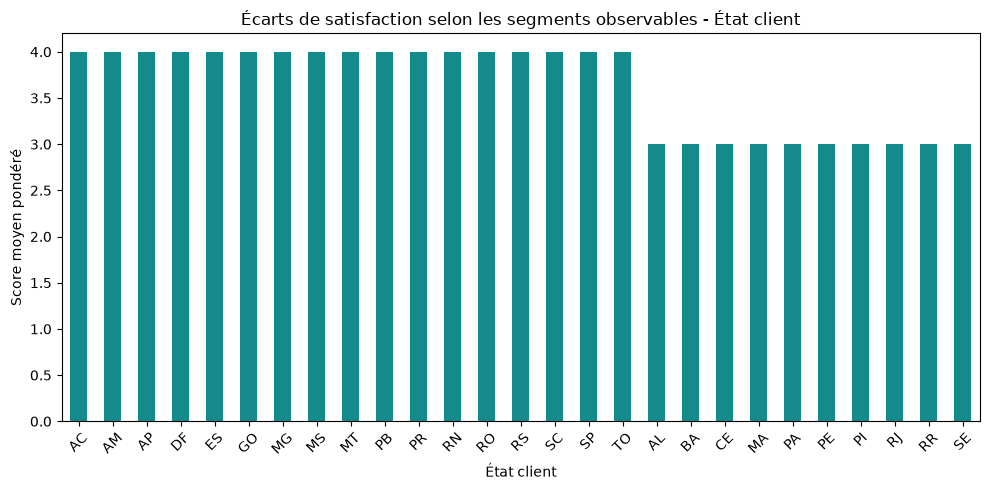

Visuel 2 - Écarts de satisfaction selon les segments observables - Ville client


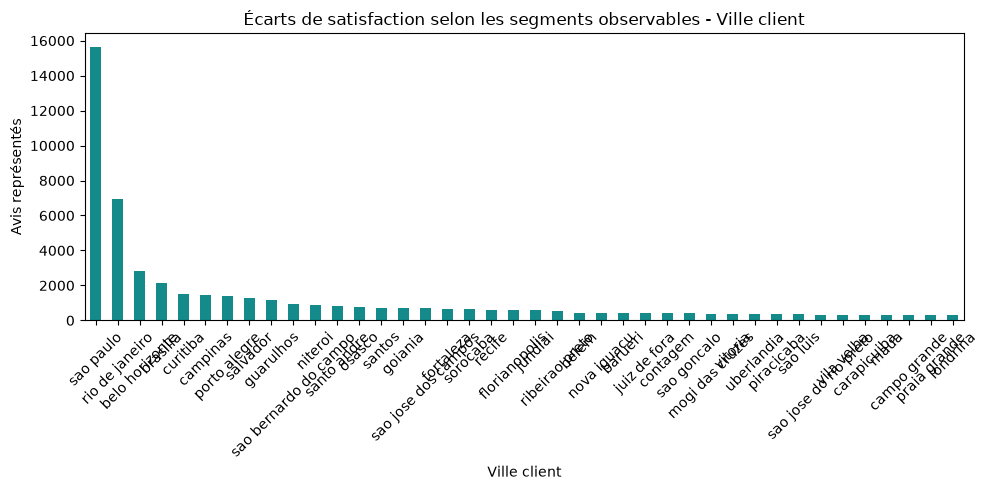

Visuel 3 - Écarts de satisfaction selon les segments observables - Code postal


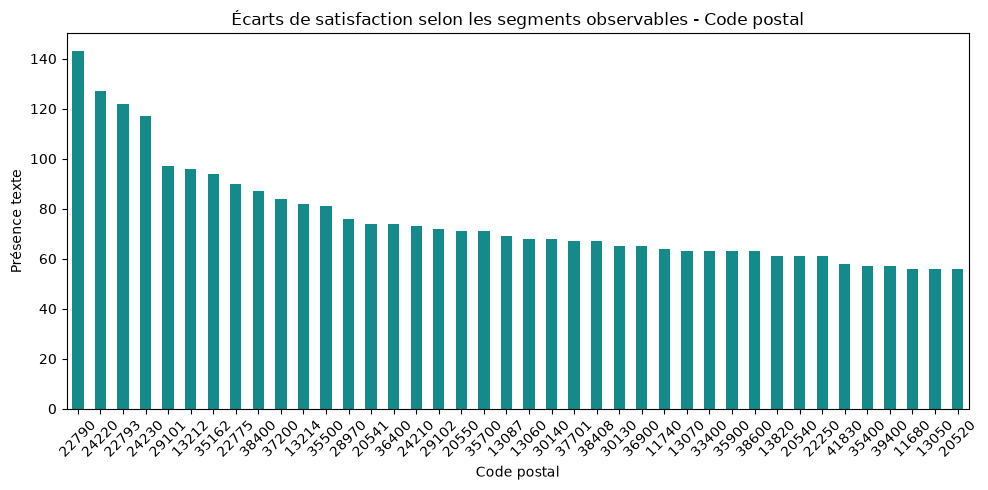

Visuel 4 - Écarts de satisfaction selon les segments observables - Statut


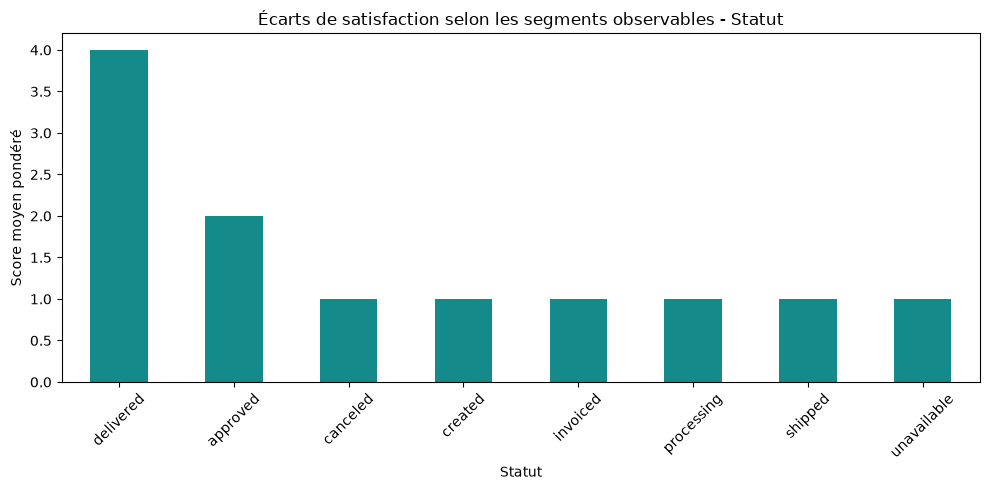

Visuel 5 - Écarts de satisfaction selon les segments observables - État x statut


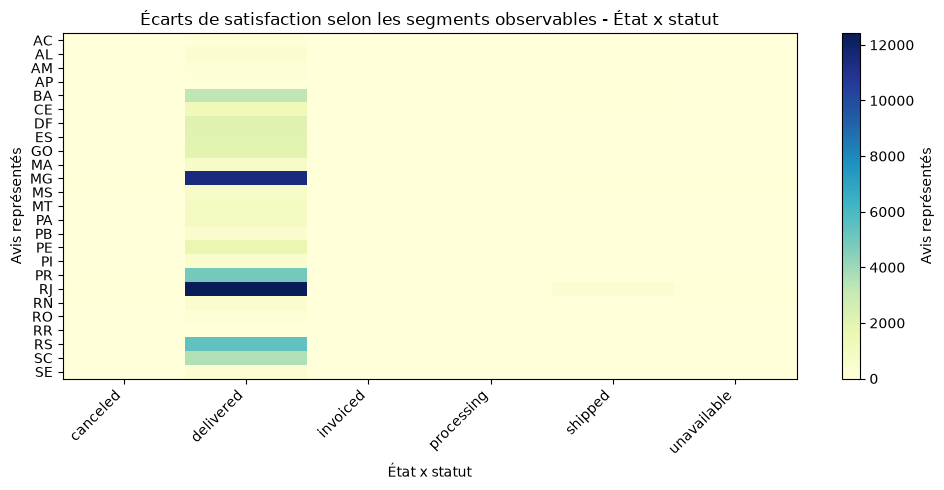

Visuel 6 - Écarts de satisfaction selon les segments observables - Ville x statut


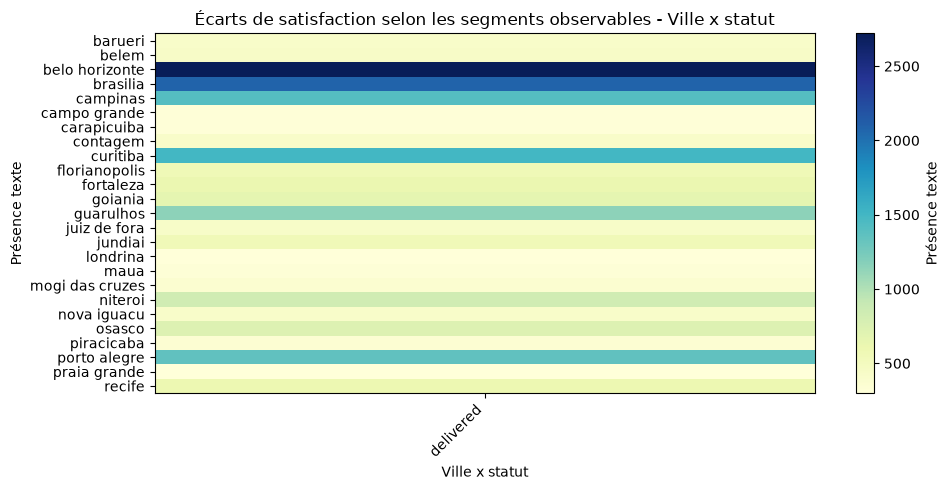

Visuel 7 - Écarts de satisfaction selon les segments observables - Mois achat


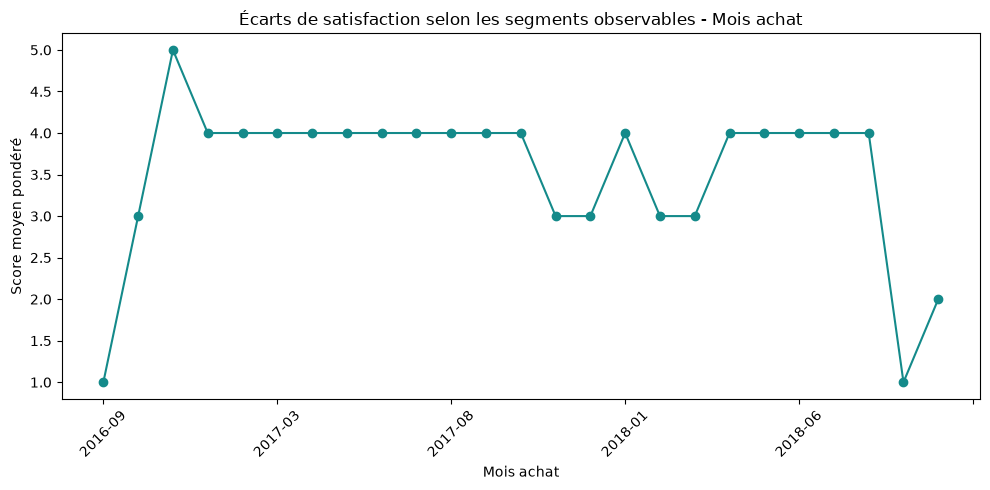

Visuel 8 - Écarts de satisfaction selon les segments observables - Mois x état


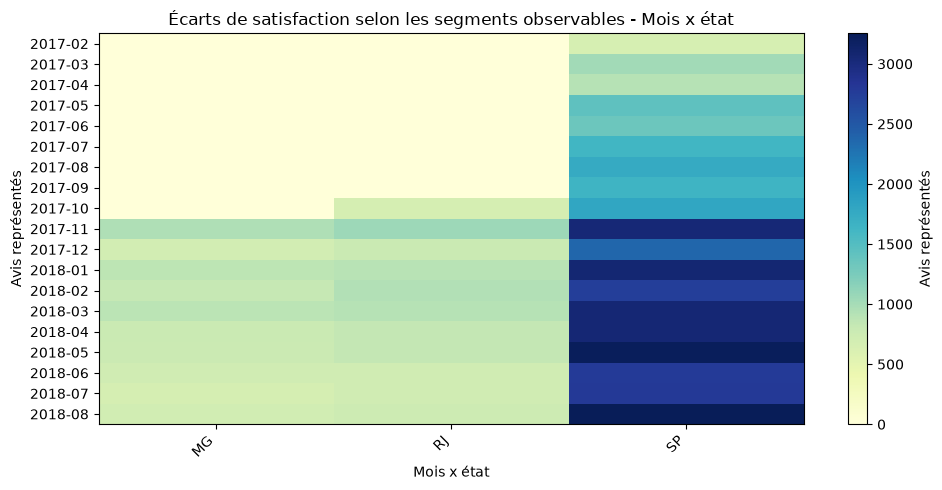

Visuel 9 - Écarts de satisfaction selon les segments observables - Jour semaine


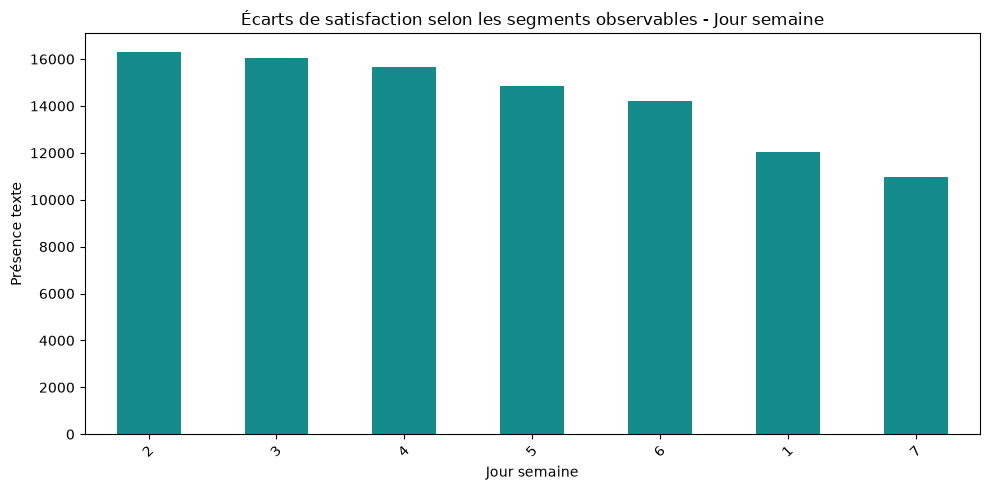

Visuel 10 - Écarts de satisfaction selon les segments observables - Client unique


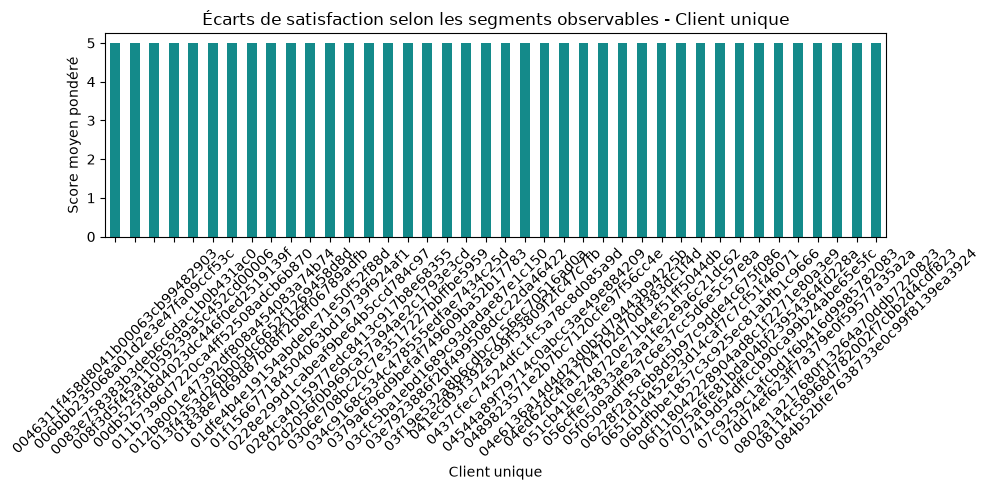

In [6]:
CHARTS=[
  {
    "n": 1,
    "title": "Écarts de satisfaction selon les segments observables - État client",
    "dim": {
      "label": "État client",
      "sql": "\"customer_state\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Score moyen pondéré",
      "sql": "SUM(\"score_sum\") / NULLIF(SUM(\"review_count\"),0)",
      "pandas": "score_sum"
    },
    "kind": "bar"
  },
  {
    "n": 2,
    "title": "Écarts de satisfaction selon les segments observables - Ville client",
    "dim": {
      "label": "Ville client",
      "sql": "\"customer_city\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Avis représentés",
      "sql": "SUM(\"review_count\")",
      "pandas": "review_count"
    },
    "kind": "bar"
  },
  {
    "n": 3,
    "title": "Écarts de satisfaction selon les segments observables - Code postal",
    "dim": {
      "label": "Code postal",
      "sql": "\"customer_zip_code\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Présence texte",
      "sql": "SUM(\"text_review_groups\")",
      "pandas": "text_review_groups"
    },
    "kind": "bar"
  },
  {
    "n": 4,
    "title": "Écarts de satisfaction selon les segments observables - Statut",
    "dim": {
      "label": "Statut",
      "sql": "\"status\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Score moyen pondéré",
      "sql": "SUM(\"score_sum\") / NULLIF(SUM(\"review_count\"),0)",
      "pandas": "score_sum"
    },
    "kind": "bar"
  },
  {
    "n": 5,
    "title": "Écarts de satisfaction selon les segments observables - État x statut",
    "dim": {
      "label": "État x statut",
      "sql": "\"customer_state\"",
      "type": "categorical",
      "series": "\"status\""
    },
    "metric": {
      "label": "Avis représentés",
      "sql": "SUM(\"review_count\")",
      "pandas": "review_count"
    },
    "kind": "heatmap"
  },
  {
    "n": 6,
    "title": "Écarts de satisfaction selon les segments observables - Ville x statut",
    "dim": {
      "label": "Ville x statut",
      "sql": "\"customer_city\"",
      "type": "categorical",
      "series": "\"status\""
    },
    "metric": {
      "label": "Présence texte",
      "sql": "SUM(\"text_review_groups\")",
      "pandas": "text_review_groups"
    },
    "kind": "heatmap"
  },
  {
    "n": 7,
    "title": "Écarts de satisfaction selon les segments observables - Mois achat",
    "dim": {
      "label": "Mois achat",
      "sql": "SUBSTRING(\"purchase_date_calendar_date\",1,7)",
      "type": "temporal",
      "series": None
    },
    "metric": {
      "label": "Score moyen pondéré",
      "sql": "SUM(\"score_sum\") / NULLIF(SUM(\"review_count\"),0)",
      "pandas": "score_sum"
    },
    "kind": "line"
  },
  {
    "n": 8,
    "title": "Écarts de satisfaction selon les segments observables - Mois x état",
    "dim": {
      "label": "Mois x état",
      "sql": "SUBSTRING(\"purchase_date_calendar_date\",1,7)",
      "type": "temporal",
      "series": "\"customer_state\""
    },
    "metric": {
      "label": "Avis représentés",
      "sql": "SUM(\"review_count\")",
      "pandas": "review_count"
    },
    "kind": "heatmap"
  },
  {
    "n": 9,
    "title": "Écarts de satisfaction selon les segments observables - Jour semaine",
    "dim": {
      "label": "Jour semaine",
      "sql": "\"purchase_date_weekday\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Présence texte",
      "sql": "SUM(\"text_review_groups\")",
      "pandas": "text_review_groups"
    },
    "kind": "bar"
  },
  {
    "n": 10,
    "title": "Écarts de satisfaction selon les segments observables - Client unique",
    "dim": {
      "label": "Client unique",
      "sql": "\"customer_unique_id\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Score moyen pondéré",
      "sql": "SUM(\"score_sum\") / NULLIF(SUM(\"review_count\"),0)",
      "pandas": "score_sum"
    },
    "kind": "bar"
  }
]
for chart in CHARTS:
    print("Visuel",chart["n"],"-",chart["title"])
    run_chart(chart)


## 5. Qualité de couverture et contrôle du modèle avis

Vérifier les volumes agrégés, la cohérence des comptes de notes et la présence de valeurs avant de présenter les résultats métier.

**Drill-down :** Modalité de score > période > statut > client; vérifier séparément fact_order pour la base totale de commandes.

Visuel 1 - Qualité de couverture et contrôle du modèle avis - Mois achat


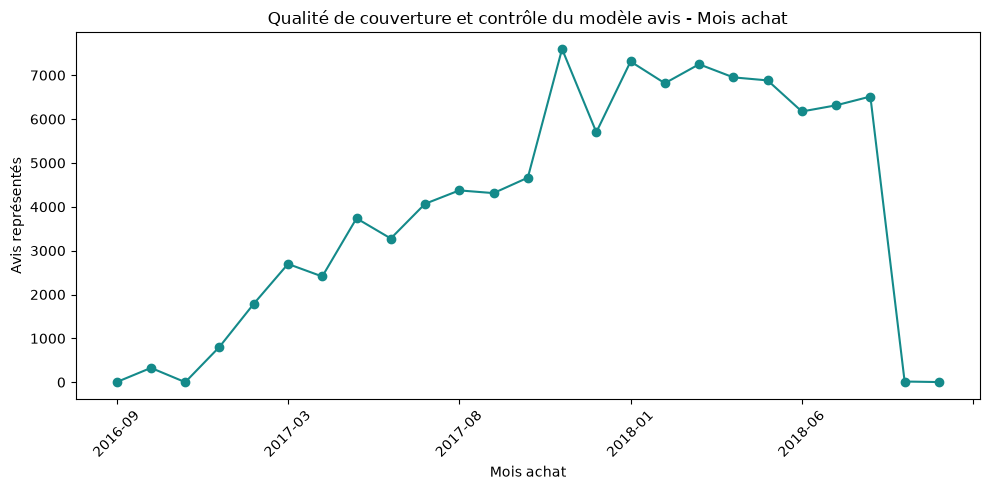

Visuel 2 - Qualité de couverture et contrôle du modèle avis - Année achat


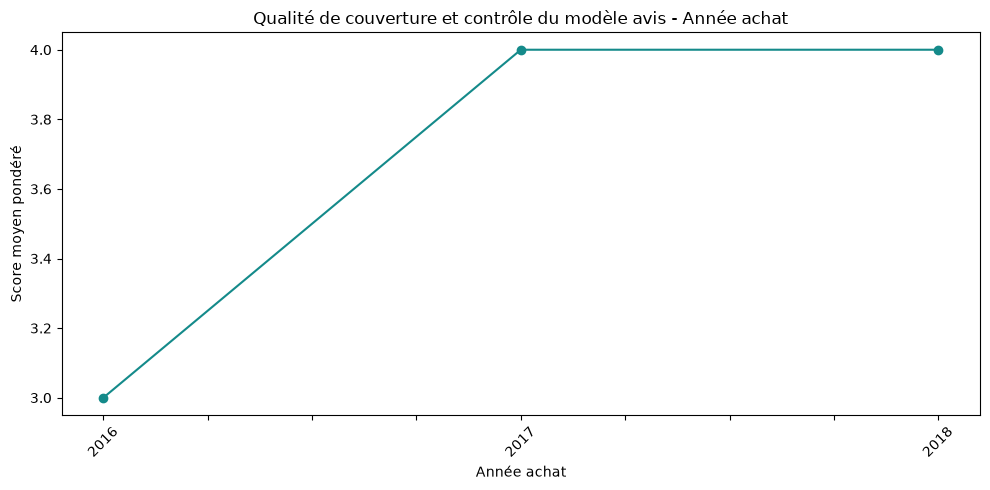

Visuel 3 - Qualité de couverture et contrôle du modèle avis - Statut


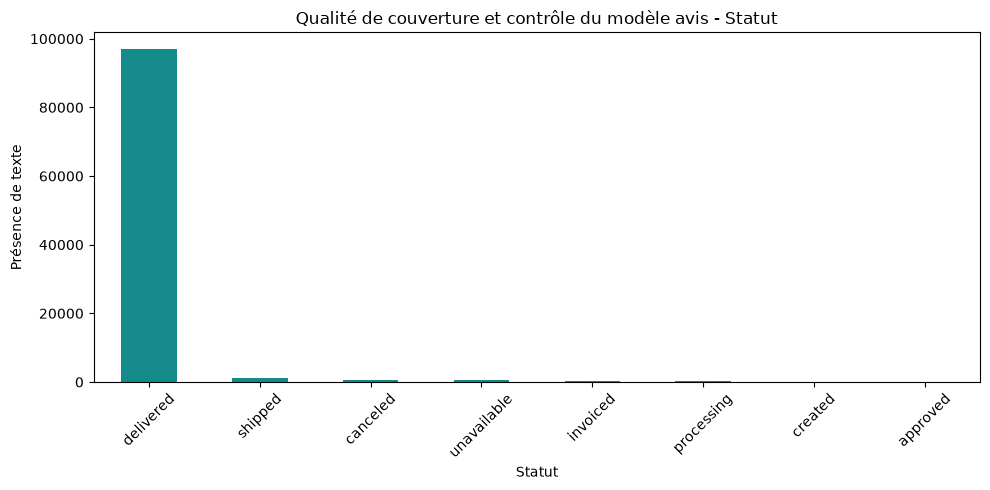

Visuel 4 - Qualité de couverture et contrôle du modèle avis - État client


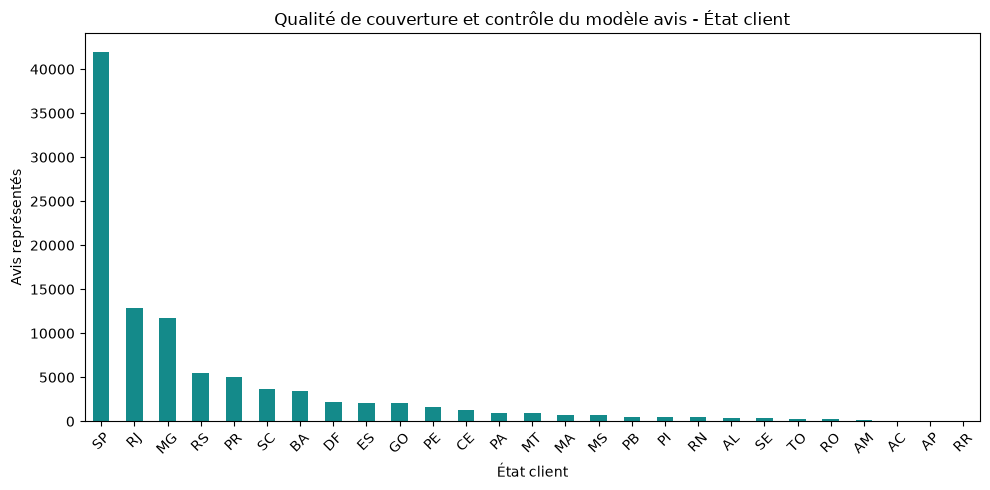

Visuel 5 - Qualité de couverture et contrôle du modèle avis - Ville client


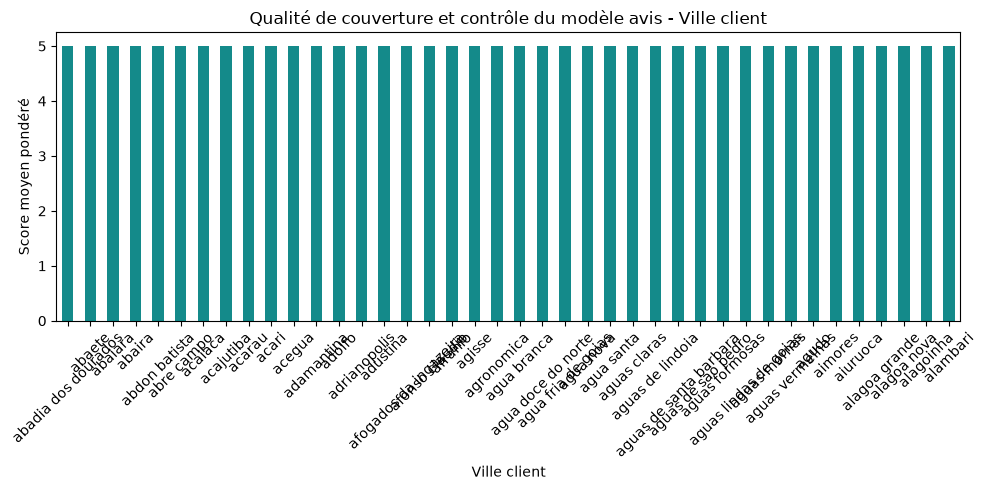

Visuel 6 - Qualité de couverture et contrôle du modèle avis - Jour semaine


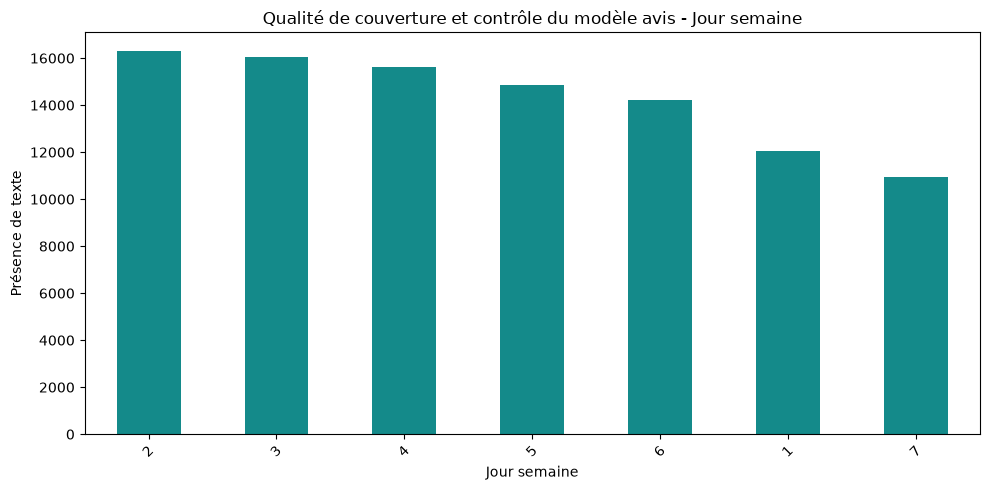

Visuel 7 - Qualité de couverture et contrôle du modèle avis - Partie du jour


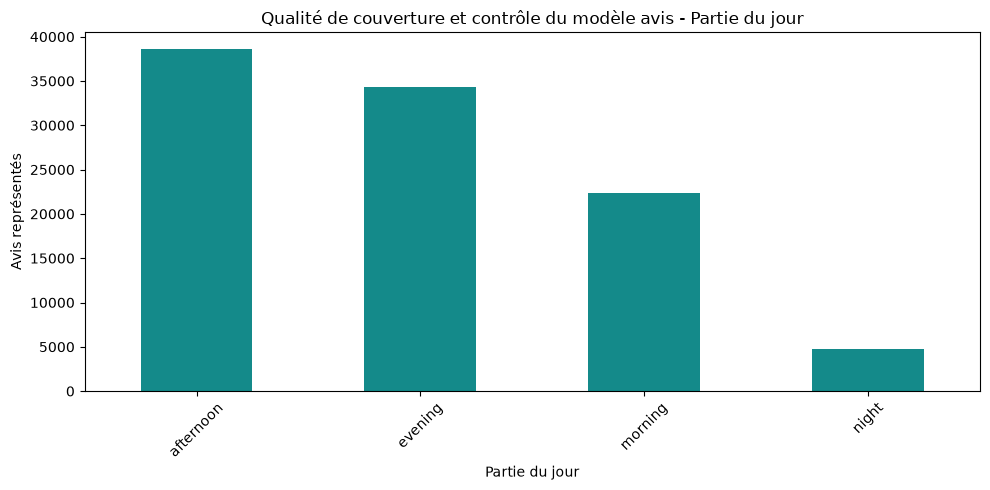

Visuel 8 - Qualité de couverture et contrôle du modèle avis - Mois x statut


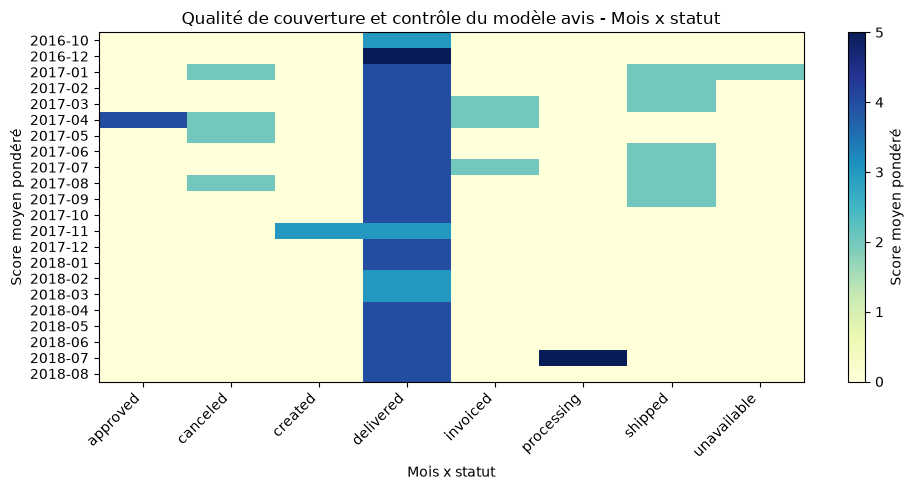

Visuel 9 - Qualité de couverture et contrôle du modèle avis - État x statut


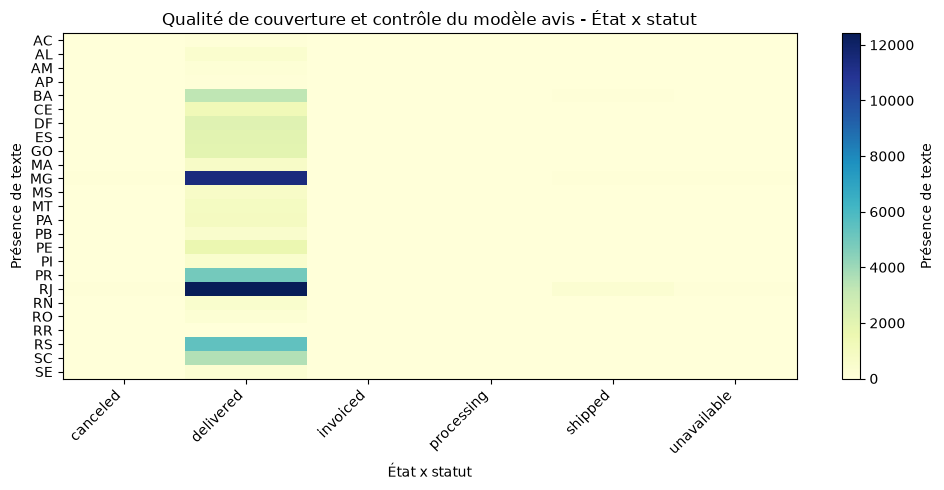

Visuel 10 - Qualité de couverture et contrôle du modèle avis - Client unique


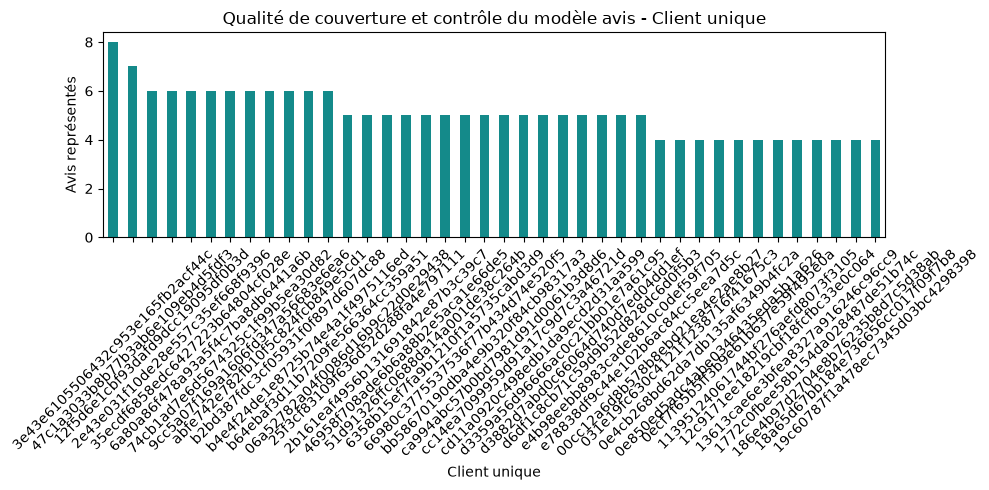

In [7]:
CHARTS=[
  {
    "n": 1,
    "title": "Qualité de couverture et contrôle du modèle avis - Mois achat",
    "dim": {
      "label": "Mois achat",
      "sql": "SUBSTRING(\"purchase_date_calendar_date\",1,7)",
      "type": "temporal",
      "series": None
    },
    "metric": {
      "label": "Avis représentés",
      "sql": "SUM(\"review_count\")",
      "pandas": "review_count"
    },
    "kind": "line"
  },
  {
    "n": 2,
    "title": "Qualité de couverture et contrôle du modèle avis - Année achat",
    "dim": {
      "label": "Année achat",
      "sql": "\"purchase_date_year\"",
      "type": "temporal",
      "series": None
    },
    "metric": {
      "label": "Score moyen pondéré",
      "sql": "SUM(\"score_sum\") / NULLIF(SUM(\"review_count\"),0)",
      "pandas": "score_sum"
    },
    "kind": "line"
  },
  {
    "n": 3,
    "title": "Qualité de couverture et contrôle du modèle avis - Statut",
    "dim": {
      "label": "Statut",
      "sql": "\"status\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Présence de texte",
      "sql": "SUM(\"text_review_groups\")",
      "pandas": "text_review_groups"
    },
    "kind": "bar"
  },
  {
    "n": 4,
    "title": "Qualité de couverture et contrôle du modèle avis - État client",
    "dim": {
      "label": "État client",
      "sql": "\"customer_state\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Avis représentés",
      "sql": "SUM(\"review_count\")",
      "pandas": "review_count"
    },
    "kind": "bar"
  },
  {
    "n": 5,
    "title": "Qualité de couverture et contrôle du modèle avis - Ville client",
    "dim": {
      "label": "Ville client",
      "sql": "\"customer_city\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Score moyen pondéré",
      "sql": "SUM(\"score_sum\") / NULLIF(SUM(\"review_count\"),0)",
      "pandas": "score_sum"
    },
    "kind": "bar"
  },
  {
    "n": 6,
    "title": "Qualité de couverture et contrôle du modèle avis - Jour semaine",
    "dim": {
      "label": "Jour semaine",
      "sql": "\"purchase_date_weekday\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Présence de texte",
      "sql": "SUM(\"text_review_groups\")",
      "pandas": "text_review_groups"
    },
    "kind": "bar"
  },
  {
    "n": 7,
    "title": "Qualité de couverture et contrôle du modèle avis - Partie du jour",
    "dim": {
      "label": "Partie du jour",
      "sql": "\"purchase_time_day_part\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Avis représentés",
      "sql": "SUM(\"review_count\")",
      "pandas": "review_count"
    },
    "kind": "bar"
  },
  {
    "n": 8,
    "title": "Qualité de couverture et contrôle du modèle avis - Mois x statut",
    "dim": {
      "label": "Mois x statut",
      "sql": "SUBSTRING(\"purchase_date_calendar_date\",1,7)",
      "type": "temporal",
      "series": "\"status\""
    },
    "metric": {
      "label": "Score moyen pondéré",
      "sql": "SUM(\"score_sum\") / NULLIF(SUM(\"review_count\"),0)",
      "pandas": "score_sum"
    },
    "kind": "heatmap"
  },
  {
    "n": 9,
    "title": "Qualité de couverture et contrôle du modèle avis - État x statut",
    "dim": {
      "label": "État x statut",
      "sql": "\"customer_state\"",
      "type": "categorical",
      "series": "\"status\""
    },
    "metric": {
      "label": "Présence de texte",
      "sql": "SUM(\"text_review_groups\")",
      "pandas": "text_review_groups"
    },
    "kind": "heatmap"
  },
  {
    "n": 10,
    "title": "Qualité de couverture et contrôle du modèle avis - Client unique",
    "dim": {
      "label": "Client unique",
      "sql": "\"customer_unique_id\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Avis représentés",
      "sql": "SUM(\"review_count\")",
      "pandas": "review_count"
    },
    "kind": "bar"
  }
]
for chart in CHARTS:
    print("Visuel",chart["n"],"-",chart["title"])
    run_chart(chart)


## Lecture des résultats\n\nComparer les valeurs aux volumes, vérifier les petits effectifs et suivre les chemins de drill-down du dossier. Les ratios et moyennes se recalculent au niveau affiché. Une association ne démontre pas une causalité.